# LAB 4. NON-PARAMETRIC METHODS

This notebook, by [felipe.alonso@urjc.es](mailto:felipe.alonso@urjc.es) and [oscar.barquero@urjc.es](mailto:oscar.barquero@urjc.es)

UPDATE: 22nd Nov 2023

In this notebook we will analyze and compare different non-parametric methods over the `pima_indian_diabetes` dataset. Specifically, we will learn:

- How to train $K-$NN, DTs, Random Forest, Gradient Boosting and MLP algorithms.
- How to set their hyperparameters (model selection)
- How to evaluate and compare their performance (model evaluation)


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# 0. Load the data 

In [2]:
path = './data/'
filename = 'pima_indian_diabetes.csv'
df = pd.read_csv(path + filename)

# take a look to the data
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# 1. Model Selection and evaluation on $K-$NN

We will focus first on the **classification task**, using `Outcome` as target

First, we split our data, but we do it wisely in order build a test set as similar as the train set. Since our target variables is *imbalaced* we might want to activate the `stratify` option.

Take a look to the function documentation: [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html?highlight=train_test_split#sklearn.model_selection.train_test_split)

In [3]:
from sklearn.model_selection import train_test_split

# Input = all the variables except the output. Output = Outcome (0 = non-diabetic, 1 = diabetic)
X = df.drop(columns='Outcome')
y = df['Outcome']

# 80% train / 20% test. stratify=y keeps the class proportion in both sets; random_state makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('- Train size:', X_train.shape)
print('- Test size:', X_test.shape)

print('\n- Train target distribution: ', y_train.value_counts().values/len(y_train))
print('- Test target distribution:  ',y_test.value_counts().values/len(y_test))

- Train size: (614, 8)
- Test size: (154, 8)

- Train target distribution:  [0.6514658 0.3485342]
- Test target distribution:   [0.64935065 0.35064935]


<div class = "alert alert-success">
Run the above cell several times, does the target variable distribution change?
</div>

In [4]:
# Run the split several times WITHOUT random_state: does the % of diabetic patients in the test set change?
# Compare a random split with a stratified one (10 repetitions each)
for strat in [None, y]:
    pct = []
    for _ in range(10):
        _, _, _, yt = train_test_split(X, y, test_size=0.2, stratify=strat)
        pct.append(100 * yt.mean())
    print("stratify =", "yes" if strat is not None else "no ", "-> % of diabetic patients in test:", np.round(pct, 1),
          "| std = %.2f" % np.std(pct))

stratify = no  -> % of diabetic patients in test: [40.3 35.1 27.9 37.  37.7 37.  31.8 35.1 40.3 37. ] | std = 3.56
stratify = yes -> % of diabetic patients in test: [35.1 35.1 35.1 35.1 35.1 35.1 35.1 35.1 35.1 35.1] | std = 0.00


**Answer.** With `random_state` fixed the split (and therefore the distribution) never changes: it is always the same. Without it, the split is different every time. In the experiment above, a **random** split gives between **29 %** and **39 %** of diabetic patients in the test set (std = 3 points), whereas the **stratified** split always gives 35.1 %, the same proportion as in the whole data set.

*Theory.* A test set of only 154 patients is a small random sample: its class proportions fluctuate by chance, so two different splits would evaluate the models on populations with different prevalence (and sensitivity, PPV or accuracy depend on it). With imbalanced classes we use **stratified sampling** so that train and test have the same distribution (the test set "looks like" the training set), which makes the estimate of the generalization error less noisy and the comparison between models fairer.

### Standarize/normalize variables

$K-$NN and MLP require the input data to be standarized

In [5]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)

X_train_norm = scaler.transform(X_train)
X_test_norm  = scaler.transform(X_test)

**Why standardize?** The models are not equally sensitive to the scale of the variables:
* **k-NN** is based on the Euclidean distance: a variable with a large range (Insulin up to 846, Glucose ~ 100) dominates the distance and the variables with a small range (DiabetesPedigreeFunction ~ 0.5) would be ignored.
* **MLP** is trained with gradient descent and its regularization ($\alpha\|\mathbf w\|^2$) depends on the scale of the inputs, so the optimization converges badly with variables of very different magnitude.
* **Trees, Random Forest and Gradient Boosting** only compare each variable with a threshold, so any monotone transformation gives exactly the same tree: they do **not** need normalization (the tree is trained with the original variables, which also makes its rules readable in clinical units).

The scaler is **fitted only with the training set** and then applied to the test set (otherwise the test mean/std would leak into the design). Note that the data of this lab are the *raw* ones: the zeros of Glucose, BloodPressure, SkinThickness, Insulin and BMI are missing values that we keep (as the lab asks); we study at the end of the notebook how much can be gained by treating them properly.

## 1.1 Let's set a baseline

Before running our algorithms it is always a good practice to build a baseline model, so you we have a reference of what the results should be.

- In `src.utils` you have implemented some functions to help us calculating and representing different classification metrics. 

- The `analyze_train_test_performance` function provides a comparative summary between training and test metrics.

PERFORMANCE METRICS
	TRAIN	TEST
ACC:	79.15	71.43
SEN:	58.88	51.85
ESP:	90.00	82.00
PPV:	75.90	60.87
F1:	66.32	56.00


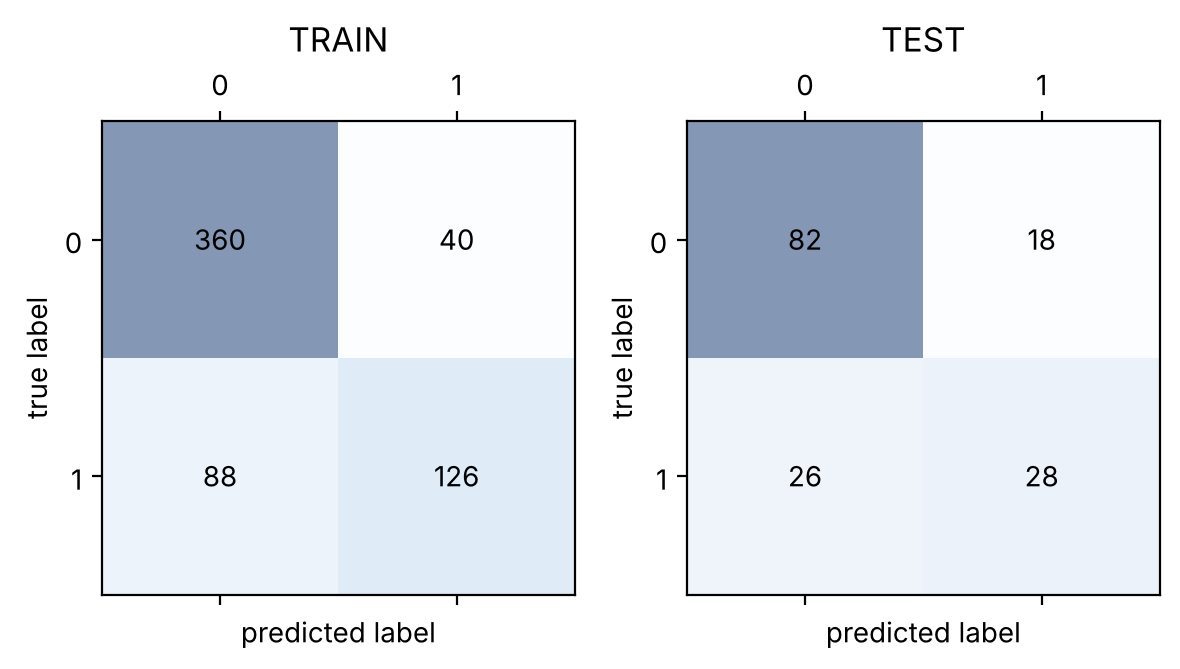

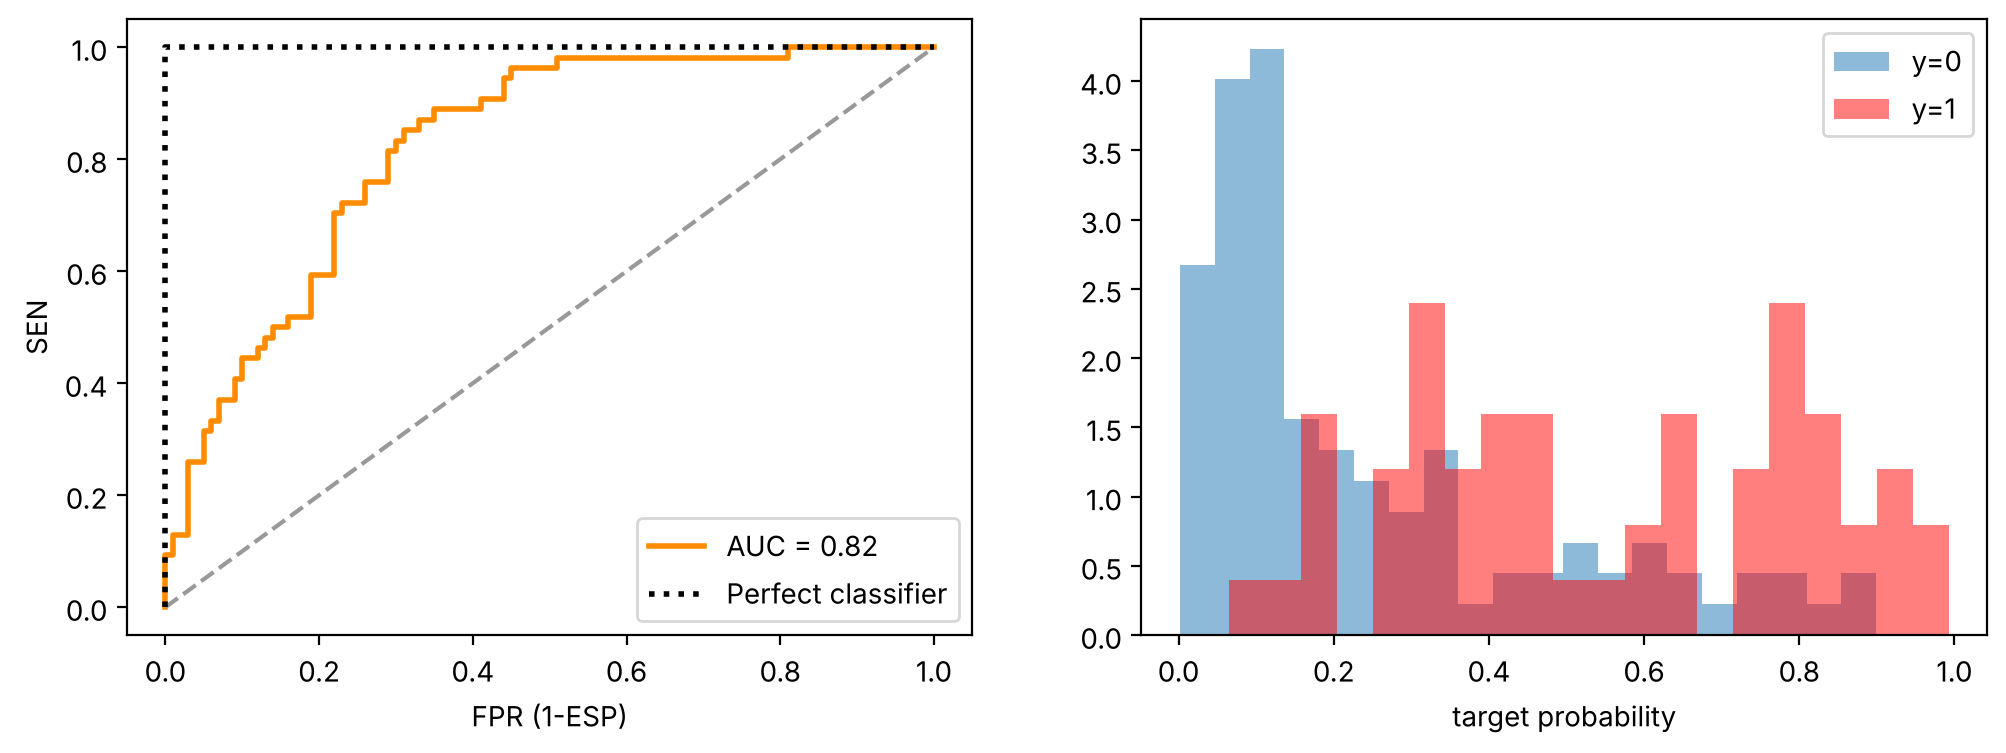

In [6]:
from sklearn.linear_model import LogisticRegression
from src.utils import analyze_train_test_performance

# Logistic regression
lr_model = LogisticRegression().fit(X_train_norm,y_train)

# This a custom function, take a look in src.utils
analyze_train_test_performance(lr_model,X_train_norm,X_test_norm,y_train,y_test)

<div class = "alert alert-success">
Does this model overfit? Justify your answer
</div>

**Answer.** The baseline logistic regression gets (train → test): accuracy 79.2 → 71.4 %, sensitivity 58.9 → 51.9 %, specificity 90.0 → 82.0 %, PPV 75.9 → 60.9 % and F1 66.3 → 56.0 %. There is a drop of 8–10 points from train to test, but this is **not strong overfitting**: logistic regression is a low-variance model (9 parameters, 614 patients) and part of the gap is the usual optimism of the training error plus the noise of a small test set (154 patients). The problem of this model is rather **bias**: even on the training set it detects only 59 % of the diabetic patients (it is a linear model with a 0.5 threshold on imbalanced classes).

This is the **reference**: a more complex model is only worth it if it clearly improves test accuracy 71.4 %, F1 56.0 % and AUC 0.823 (always predicting "non-diabetic" would give 65 % accuracy).

## 1.2 Model selection: *GridSearch* 

We are going to sweep different values of the parameters of each algorithm, to determine its optimal value. In this sweep, we will use a cross-validation strategy, but never the test set!

To do so, we will be using the [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html?highlight=gridsearchcv#sklearn.model_selection.GridSearchCV) function.

In [7]:
from sklearn.model_selection import GridSearchCV

# These are customized functions: should be in utils.py
def hyper_parameters_search(clf, X, y, param_grid, scorer = 'f1', cv=5):
    
    grid = GridSearchCV(clf, param_grid = param_grid, scoring = scorer, cv = cv)
    grid.fit(X, y)

    print("best mean cross-validation score: {:.3f}".format(grid.best_score_))
    print("best parameters: {}".format(grid.best_params_))
    
    return grid

def plot_cv_scoring(grid, hyper_parameter, scorer = 'f1', plot_errors = False, log=False):
    
    scores = np.array(grid.cv_results_['mean_test_score'])
    std_scores = grid.cv_results_['std_test_score']
        
    params = grid.param_grid[hyper_parameter]
    
    if log:
        params = np.log10(params)
    
    if plot_errors:
        plt.errorbar(params,scores,yerr=std_scores, fmt='o-',ecolor='g')
    else:
        plt.plot(params,scores, 'o-')
    plt.xlabel(hyper_parameter,fontsize=14)
    plt.ylabel(scorer)
    plt.show()

#### Train an algorithm using `GridSearchCV`

We need to define:

- `scoring`: strategy to evaluate the performance of the cross-validated model on the validation sets. [Metrics in sklearn](https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter)

<div class = "alert alert-success">
Take a look to the different metrics in sklearn
</div>

- `param_grid`: dictionary with parameters names (`str`) as keys and lists of parameter settings to try as value. Example:

```python
param_grid = {'n_neighbors': range(1,25)}
```




### $K-$NN

best mean cross-validation score: 0.613
best parameters: {'n_neighbors': 7}


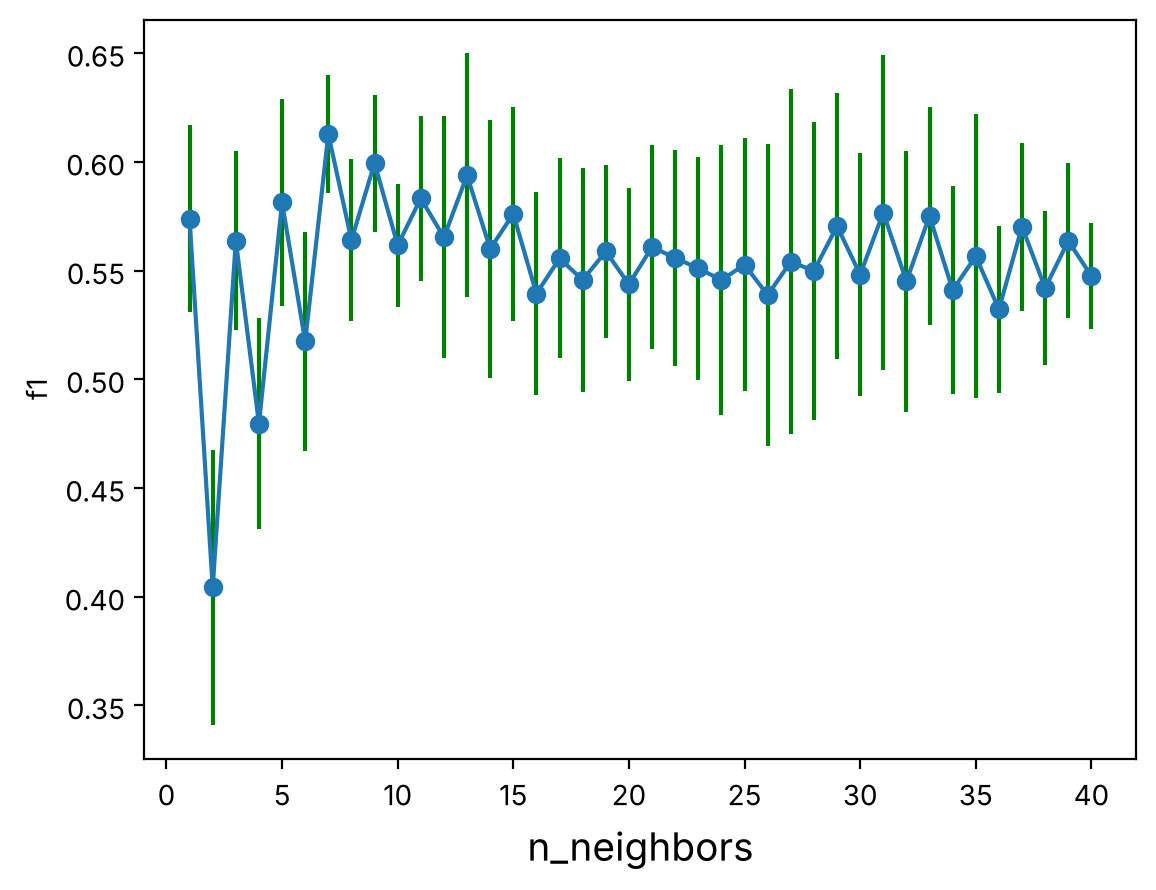

In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Metric for the scoring: F1 of the positive (minority) class. Other possibilities: accuracy, balanced_accuracy, f1, roc_auc, ....
scorer = 'f1'

# param_grid: number of neighbours k from 1 to 40
param_grid = {'n_neighbors': range(1, 41)}

# Our customized function (5-fold stratified cross-validation on the TRAINING set, never the test set)
grid_knn = hyper_parameters_search(KNeighborsClassifier(), X_train_norm, y_train, param_grid, scorer=scorer, cv=5)

# do the plotting
plot_cv_scoring(grid_knn,'n_neighbors',scorer, plot_errors=True)

accuracy           best k = 31 | best CV score = 0.764


balanced_accuracy  best k =  7 | best CV score = 0.708


f1                 best k =  7 | best CV score = 0.613


roc_auc            best k = 27 | best CV score = 0.825


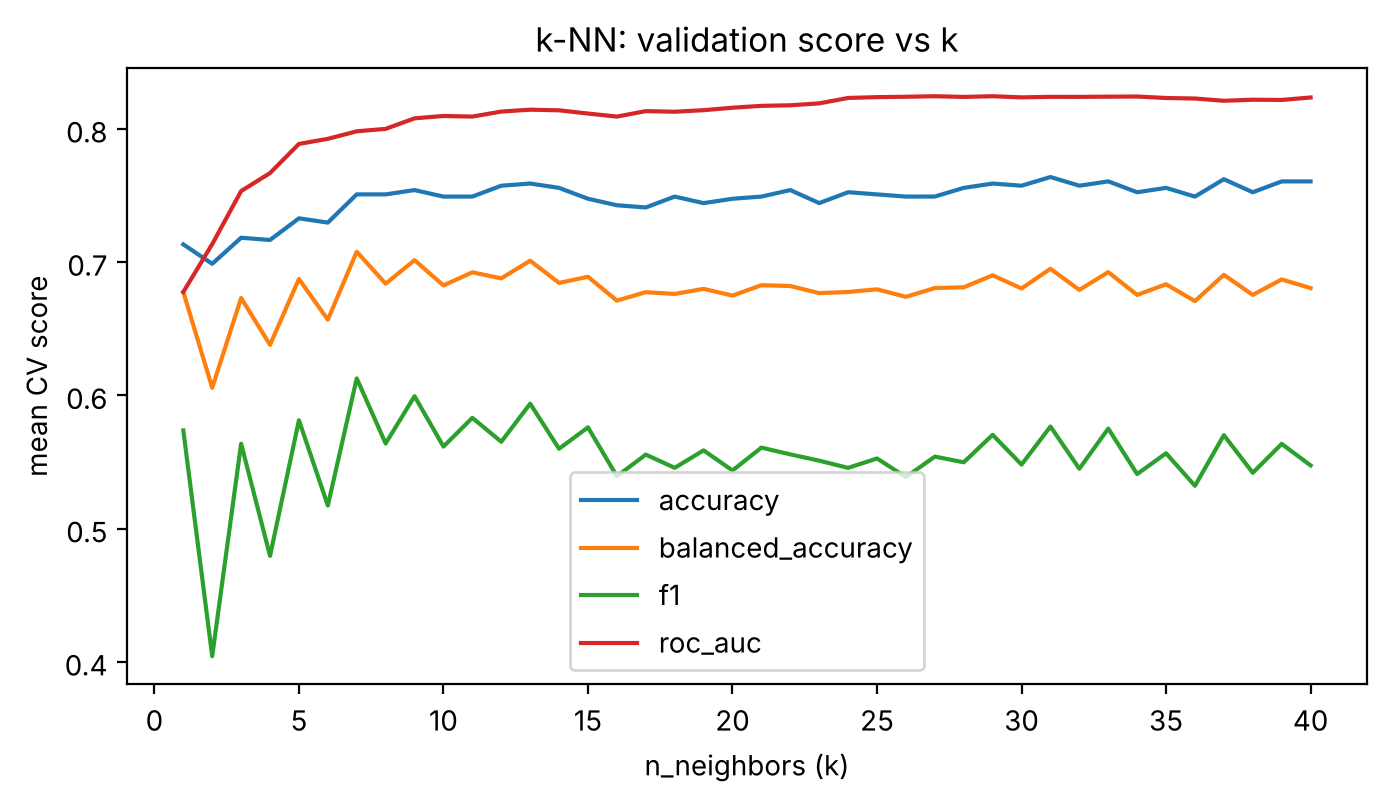

In [9]:
# Different score metrics to guide the CV process: do they select the same k?
from sklearn.model_selection import GridSearchCV
plt.figure(figsize=(8, 4))
for s in ['accuracy', 'balanced_accuracy', 'f1', 'roc_auc']:
    g = GridSearchCV(KNeighborsClassifier(), param_grid, scoring=s, cv=5).fit(X_train_norm, y_train)
    plt.plot(list(param_grid['n_neighbors']), g.cv_results_['mean_test_score'], label=s)
    print(f"{s:18s} best k = {g.best_params_['n_neighbors']:2d} | best CV score = {g.best_score_:.3f}")
plt.xlabel('n_neighbors (k)'); plt.ylabel('mean CV score'); plt.legend(); plt.title('k-NN: validation score vs k')
plt.show()

<div class = "alert alert-success">

Which is the optimal value for $k$? You might want to consider
    
- Different score metrics to guide the CV process<br> 
- Plot the CV errors (`plot_errors = True`) 
</div>

**Optimal k.** It depends on the metric that guides the cross-validation: **accuracy → k = 31, AUC → k = 27, F1 and balanced accuracy → k = 7**. Accuracy and AUC (dominated by the majority class and by the ranking of the scores) prefer smooth models with many neighbours; F1 and balanced accuracy, which put the weight on the diabetic class, prefer a small k, because with large k the majority class "wins" almost all the votes and the sensitivity drops. Since the classes are imbalanced and we care about detecting the diabetic patients, we choose the **F1 curve → k = 7** (CV F1 = 0.613 ± 0.027, versus 0.55–0.60 for most of the other k). The error bars show that the differences between neighbouring values of k are small compared with the CV standard deviation (0.03–0.05), so the choice is not very sharp.

*Theory.* $k$ is the number of neighbours that vote: the prediction is the majority class (or the fraction of each class, as soft output) among the $k$ closest training patients. **Small k = flexible model** (low bias, high variance): with k = 1 the training accuracy is 100 % but the test accuracy is 70.8 % and the AUC only 0.67 (overfitting, the model memorizes the noise). **Large k = smooth model** (high bias, low variance) that tends to the majority class (k = N always predicts the most frequent class). The best k is a compromise that is searched with cross-validation on the training set, never on the test set.

## 1.3 Model evaluation

Once we have selected the model (hyper)-parameters, we evaluate its performance

Chosen k: {'n_neighbors': 7}
PERFORMANCE METRICS
	TRAIN	TEST
ACC:	80.62	74.68
SEN:	65.42	57.41
ESP:	88.75	84.00
PPV:	75.68	65.96
F1:	70.18	61.39


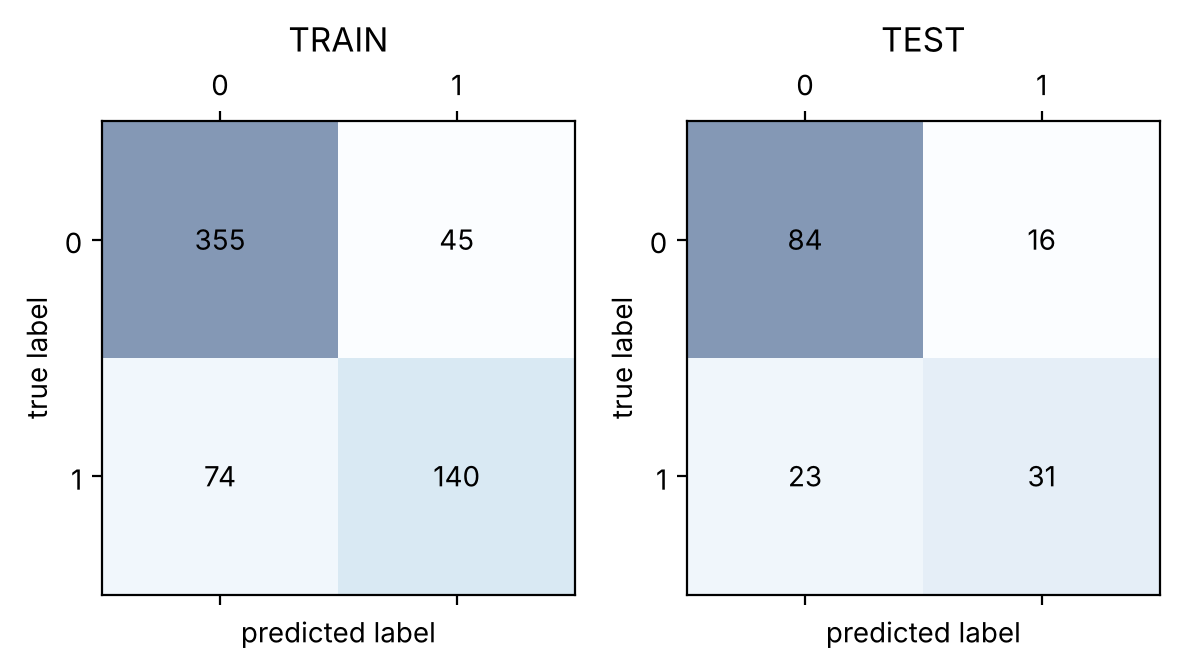

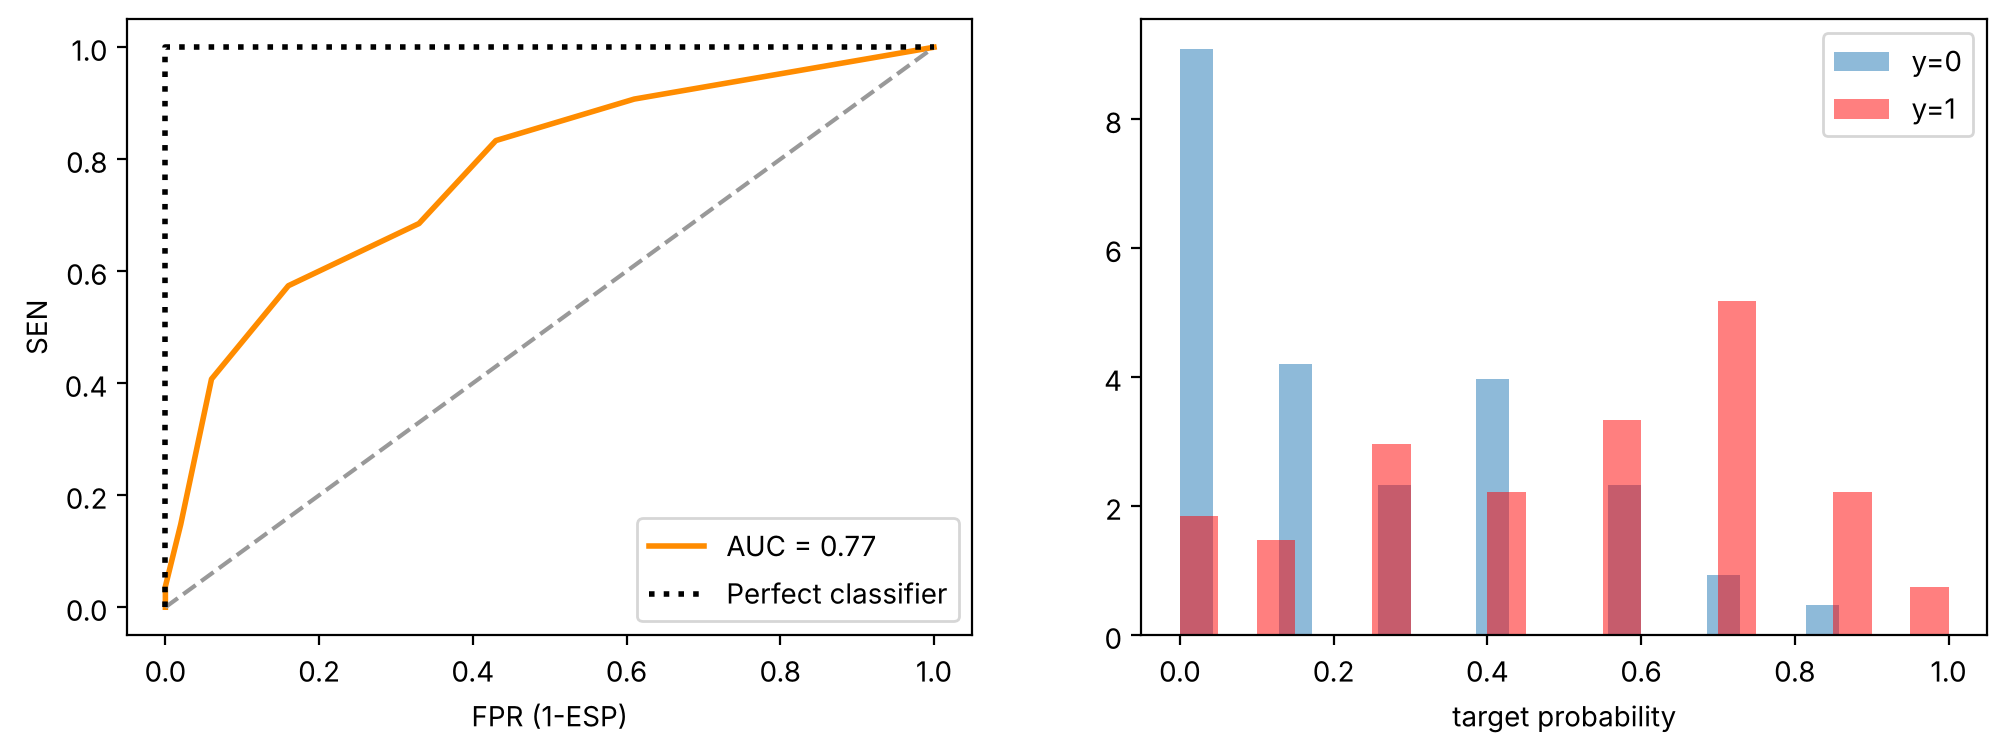

In [10]:
knn_model = KNeighborsClassifier(**grid_knn.best_params_).fit(X_train_norm, y_train)
print("Chosen k:", grid_knn.best_params_)

analyze_train_test_performance(knn_model,X_train_norm,X_test_norm,y_train,y_test)

<div class = "alert alert-success">
Does this model overfit? Is it better than our baseline?
</div>

**Answer.** With k = 7: train → test accuracy 80.6 → 74.7 %, sensitivity 65.4 → 57.4 %, F1 70.2 → 61.4 %: a gap of 6–9 points, so there is **some overfitting** (expected from a local method with a small k, whose training error is optimistic because each training patient is one of its own neighbours).

**Better than the baseline?** On the hard metrics, slightly: accuracy 74.7 vs 71.4 %, sensitivity 57.4 vs 51.9 %, F1 61.4 vs 56.0 %. But its **AUC is lower (0.774 vs 0.823)**: with k = 7 the soft output only takes 8 different values (0, 1/7, …, 1), so the ROC curve is very coarse. With only 154 test patients, a difference of 3 points of accuracy is about 5 patients, so we cannot call it a clear improvement.

# 2. Decision trees (DTs)

We will repeat the above process for DTs. In this case, the hyper-parameter is `max_depth`.

## 2.1 Model selection

best mean cross-validation score: 0.753
best parameters: {'max_depth': 2}


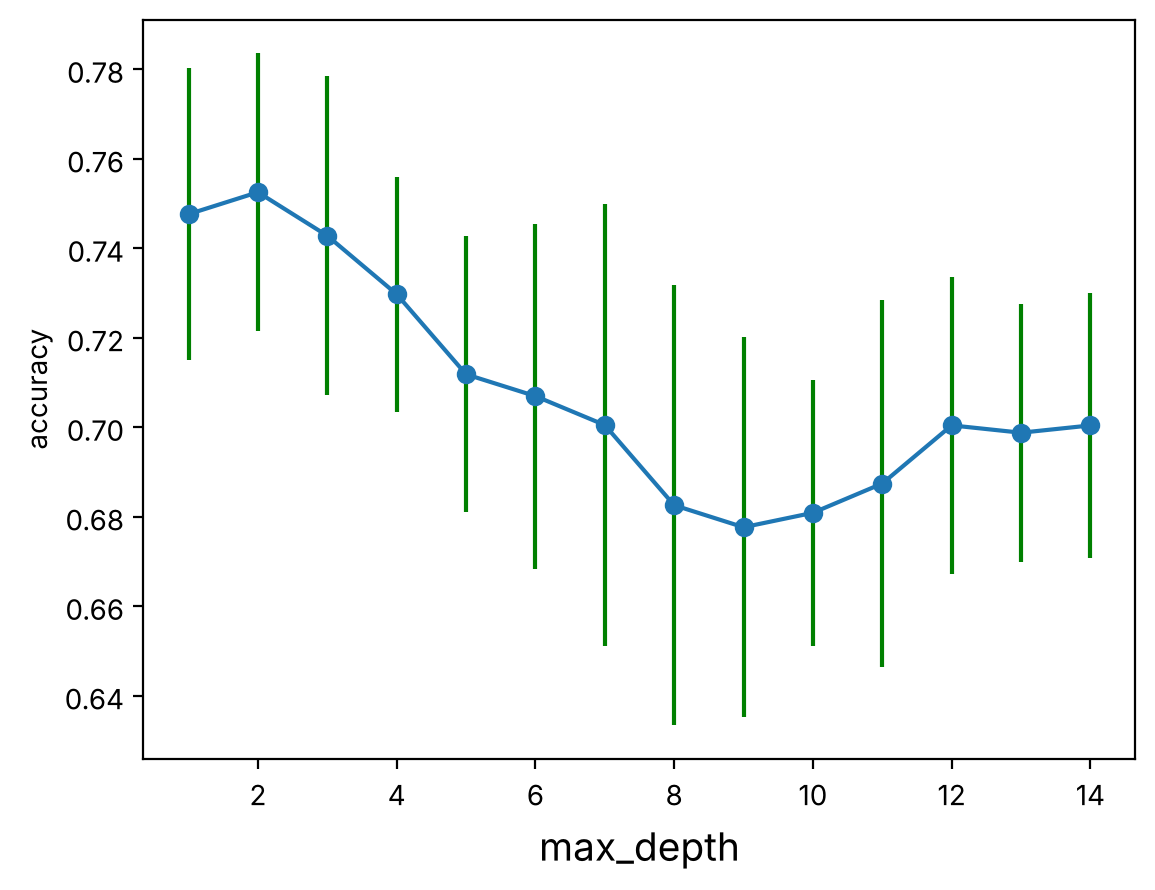

best mean cross-validation score: 0.576
best parameters: {'max_depth': 4}


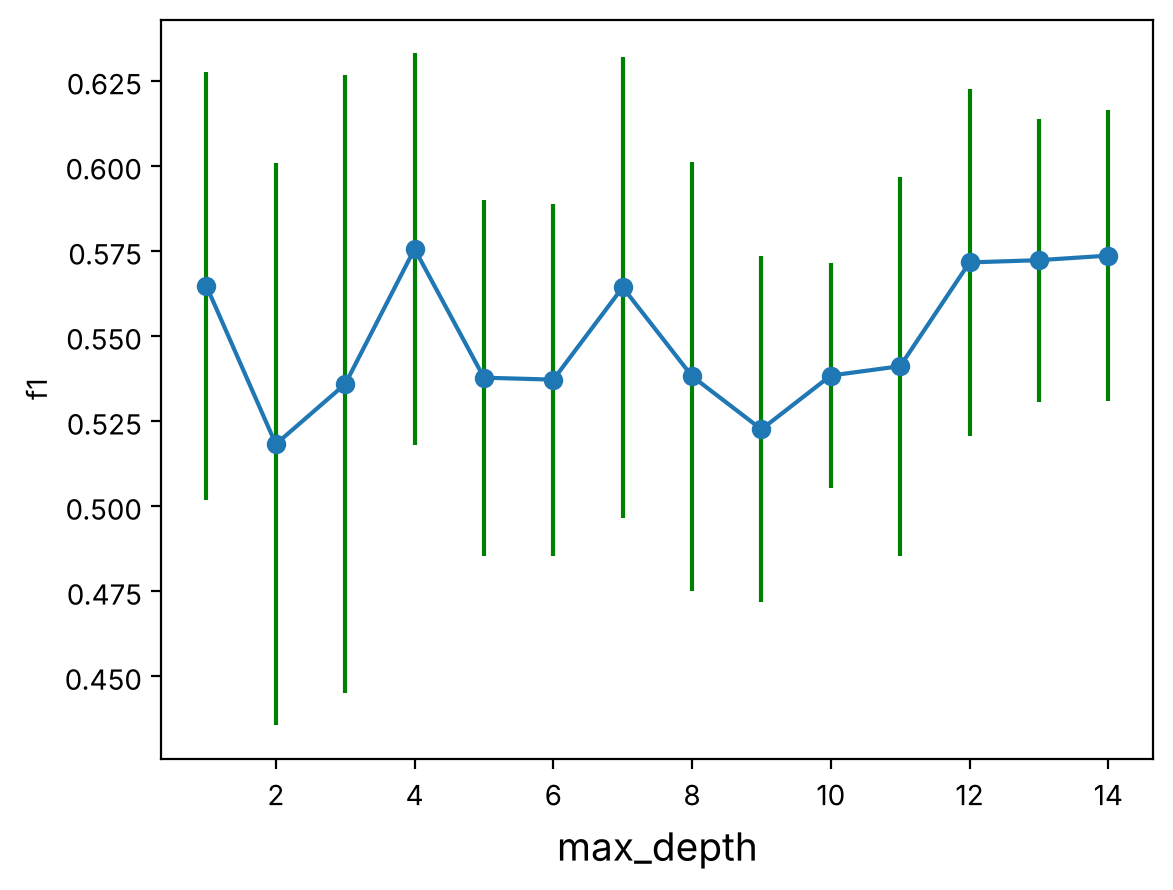

In [11]:
from sklearn.tree import DecisionTreeClassifier

# Decision trees: max_depth and, as the other hyper-parameter, min_samples_leaf (first one at a time)
param_grid = {'max_depth': range(1,15)}

scorer = 'accuracy'

#HYPER PARAMETER SEARCH (trees do not need normalized data -> X_train)
grid_dt = hyper_parameters_search(DecisionTreeClassifier(random_state=0), X_train, y_train, param_grid, scorer=scorer)

# do the plotting
plot_cv_scoring(grid_dt,'max_depth',scorer, plot_errors=True)

# The same with the F1 of the diabetic class (the classes are imbalanced)
grid_dt_f1 = hyper_parameters_search(DecisionTreeClassifier(random_state=0), X_train, y_train, param_grid, scorer='f1')
plot_cv_scoring(grid_dt_f1,'max_depth','f1', plot_errors=True)

best mean cross-validation score: 0.628
best parameters: {'min_samples_leaf': 30}


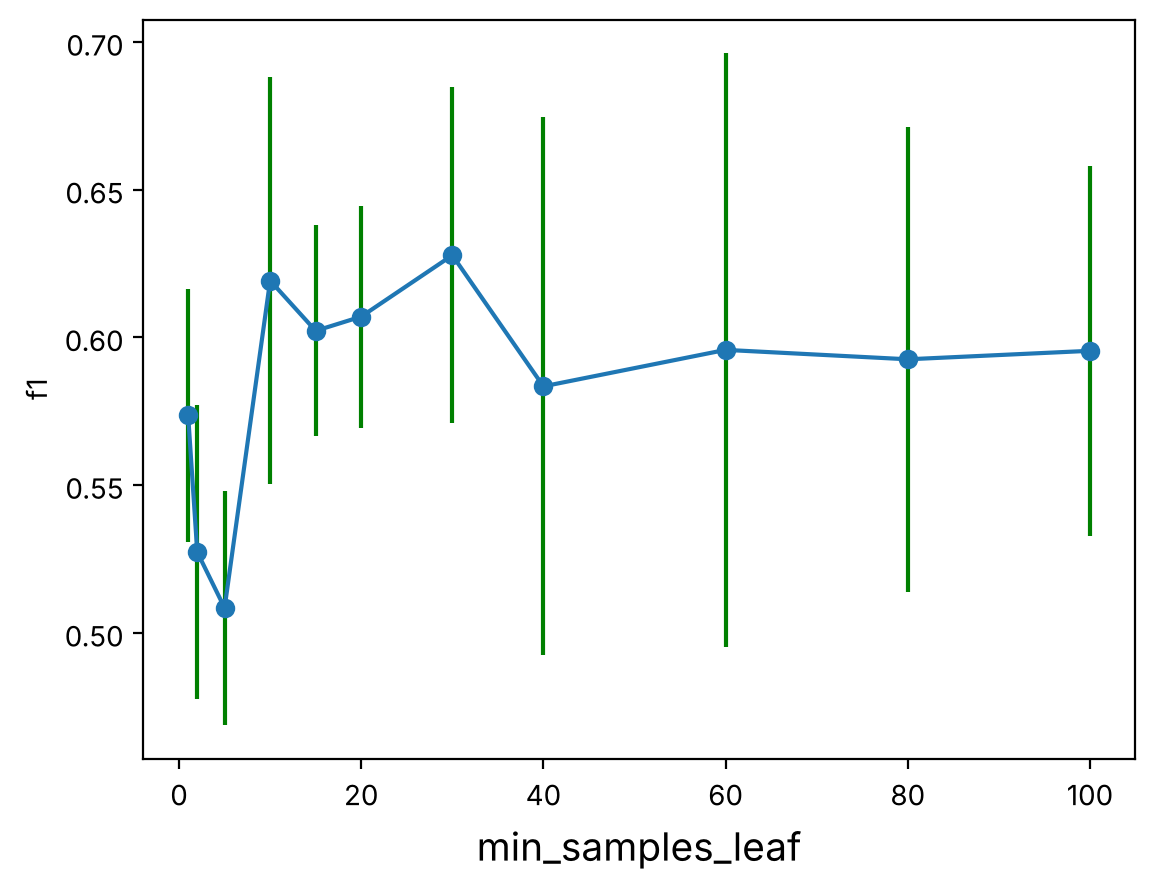

best mean cross-validation score: 0.653
best parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 30}


In [12]:
# Other hyper-parameter: minimum number of samples per leaf (the larger, the simpler the tree)
param_grid_leaf = {'min_samples_leaf': [1, 2, 5, 10, 15, 20, 30, 40, 60, 80, 100]}
grid_dt_leaf = hyper_parameters_search(DecisionTreeClassifier(random_state=0), X_train, y_train, param_grid_leaf, scorer='f1')
plot_cv_scoring(grid_dt_leaf,'min_samples_leaf','f1', plot_errors=True)

# Both together (and the splitting criterion) -> final tree. Score: F1 of the diabetic class
param_grid_dt = {'max_depth': range(1, 11), 'min_samples_leaf': [1, 5, 10, 20, 30, 40, 60], 'criterion': ['gini', 'entropy']}
grid_dt_full = hyper_parameters_search(DecisionTreeClassifier(random_state=0), X_train, y_train, param_grid_dt, scorer='f1')

## 2.2 Model evaluation

Chosen hyper-parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 30} | depth = 4 | leaves = 9
PERFORMANCE METRICS
	TRAIN	TEST
ACC:	78.34	80.52
SEN:	68.69	68.52
ESP:	83.50	87.00
PPV:	69.01	74.00
F1:	68.85	71.15


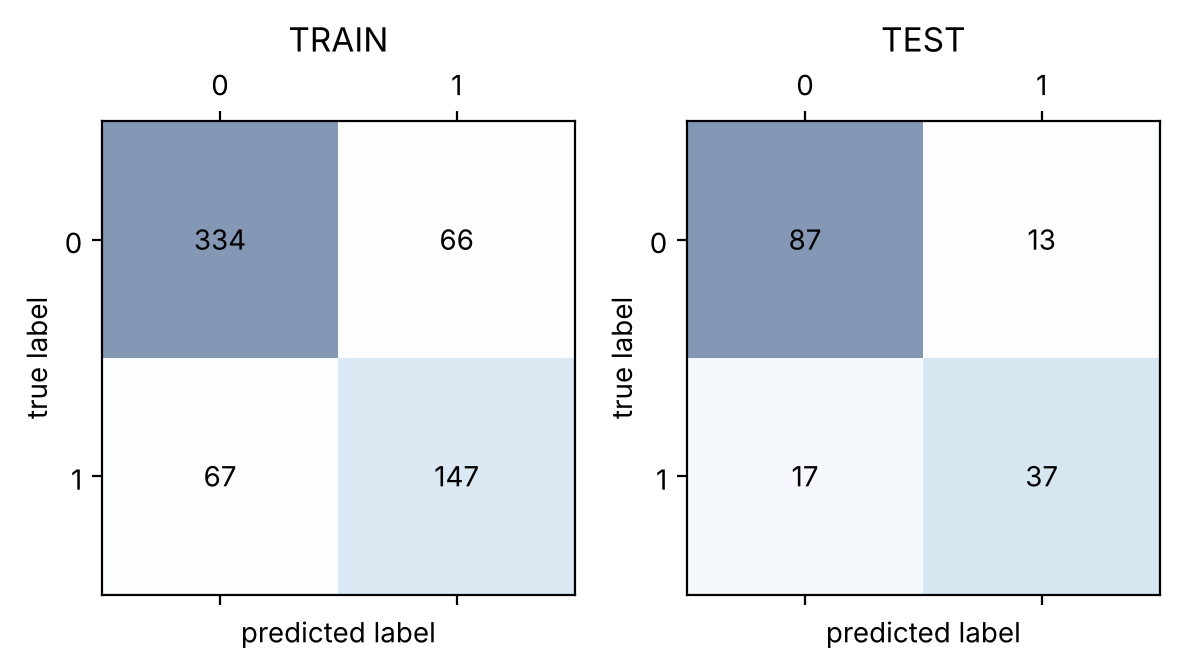

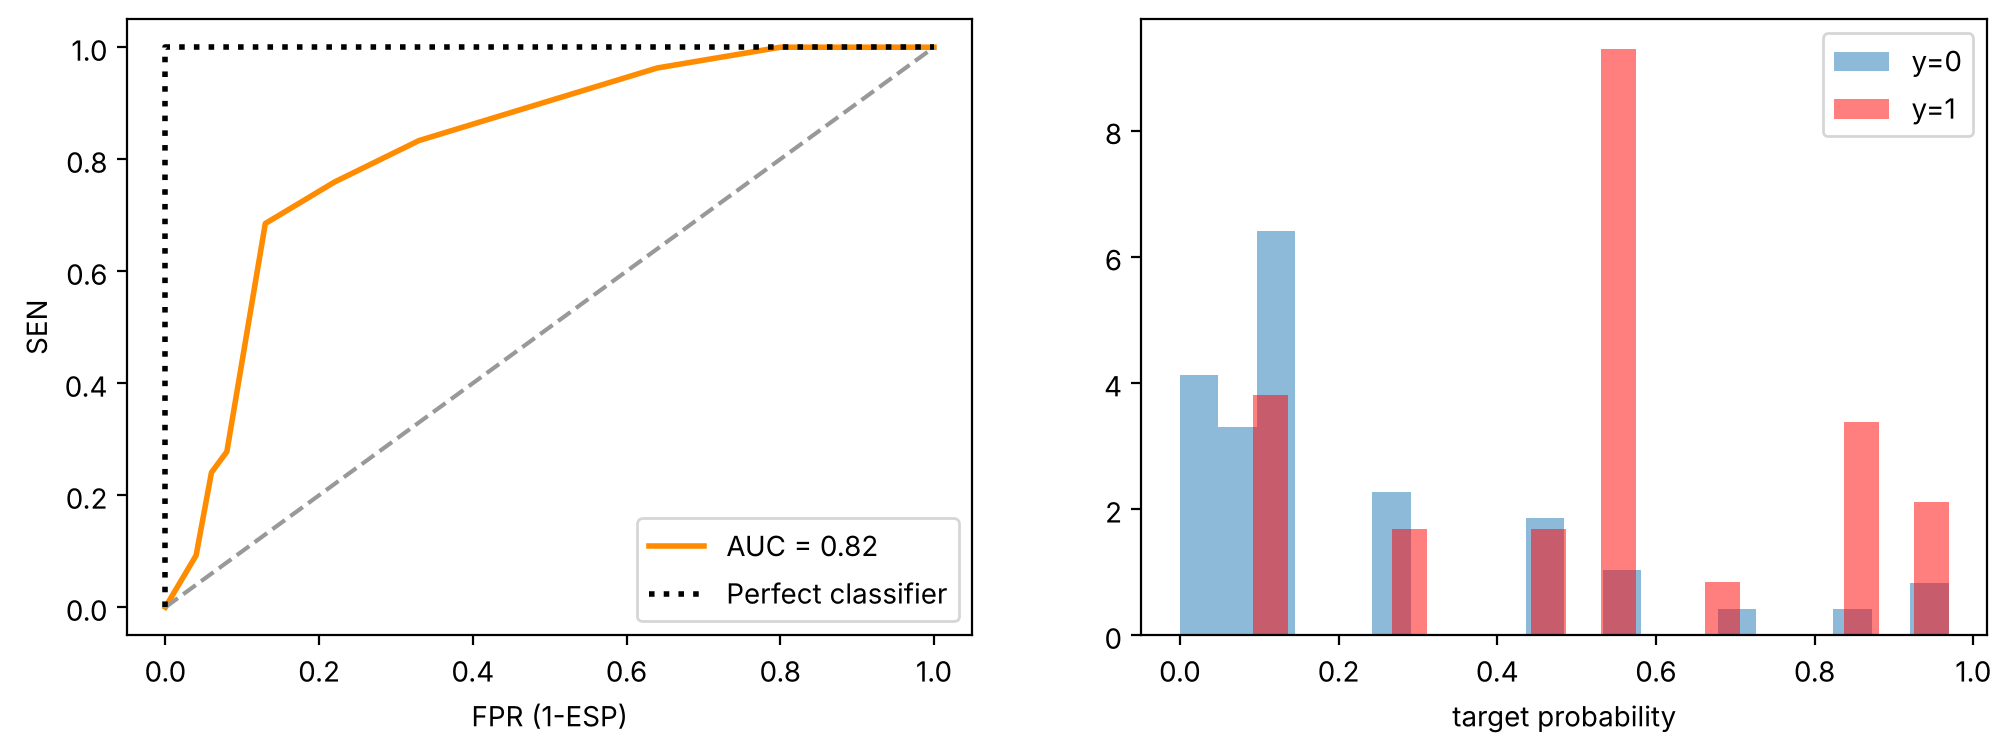

In [13]:
dt_model = DecisionTreeClassifier(random_state=0, **grid_dt_full.best_params_).fit(X_train, y_train)
print("Chosen hyper-parameters:", grid_dt_full.best_params_, "| depth =", dt_model.get_depth(), "| leaves =", dt_model.get_n_leaves())

analyze_train_test_performance(dt_model,X_train,X_test,y_train,y_test)

<div class = "alert alert-success">

- Does this model overfit? 
- Is it better than our baseline?
- What if we change `max_depth`?

</div>

In [14]:
# What if we change max_depth? (the other hyper-parameters as chosen). Train vs test: accuracy and F1 of the diabetic class
from sklearn.metrics import accuracy_score, f1_score
rows = []
for d in [1, 2, 3, 4, 5, 8, 12, None]:
    m = DecisionTreeClassifier(random_state=0, **{**grid_dt_full.best_params_, 'max_depth': d}).fit(X_train, y_train)
    rows.append({'max_depth': d if d is not None else 'None', 'leaves': m.get_n_leaves(),
                 'train acc': accuracy_score(y_train, m.predict(X_train)), 'test acc': accuracy_score(y_test, m.predict(X_test)),
                 'train F1': f1_score(y_train, m.predict(X_train)), 'test F1': f1_score(y_test, m.predict(X_test))})
pd.DataFrame(rows).set_index('max_depth').round(3)

,leaves,train acc,test acc,train F1,test F1
max_depth,,,,,
1,2,0.761,0.695,0.530,0.390
2,4,0.761,0.695,0.530,0.390
3,7,0.761,0.695,0.530,0.390
4,9,0.783,0.805,0.689,0.712
5,12,0.795,0.773,0.682,0.646
8,15,0.796,0.747,0.652,0.562
12,15,0.796,0.747,0.652,0.562
None,15,0.796,0.747,0.652,0.562


Fully grown tree: depth = 16 | leaves = 114
PERFORMANCE METRICS
	TRAIN	TEST
ACC:	100.00	73.38
SEN:	100.00	48.15
ESP:	100.00	87.00
PPV:	100.00	66.67
F1:	100.00	55.91


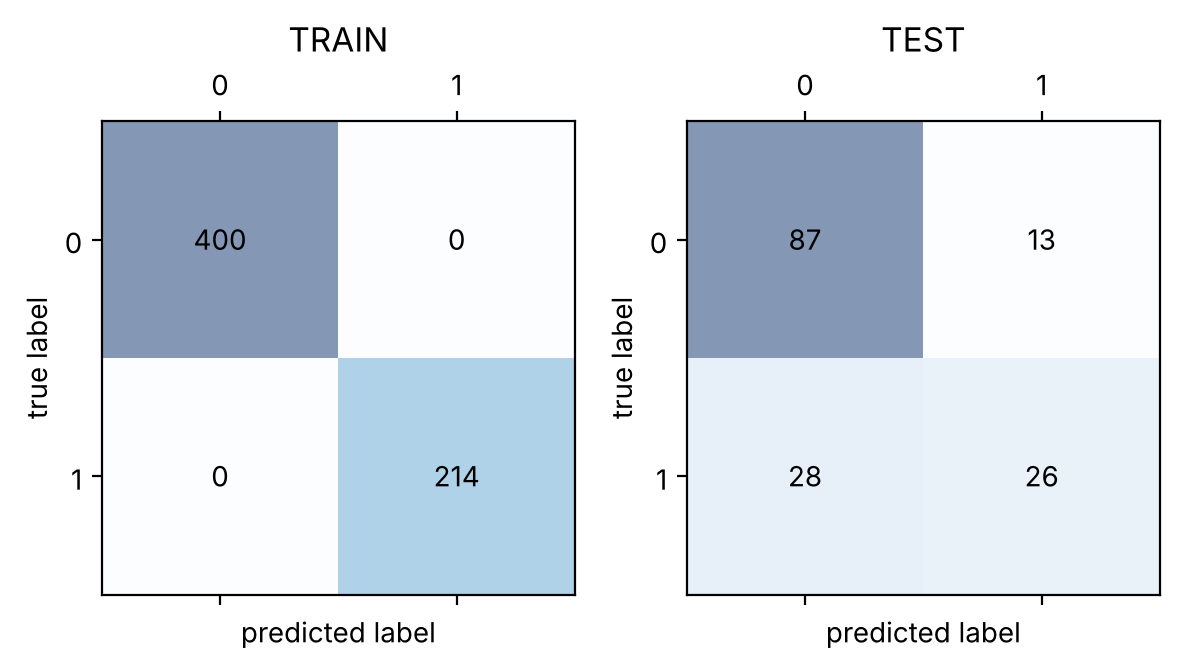

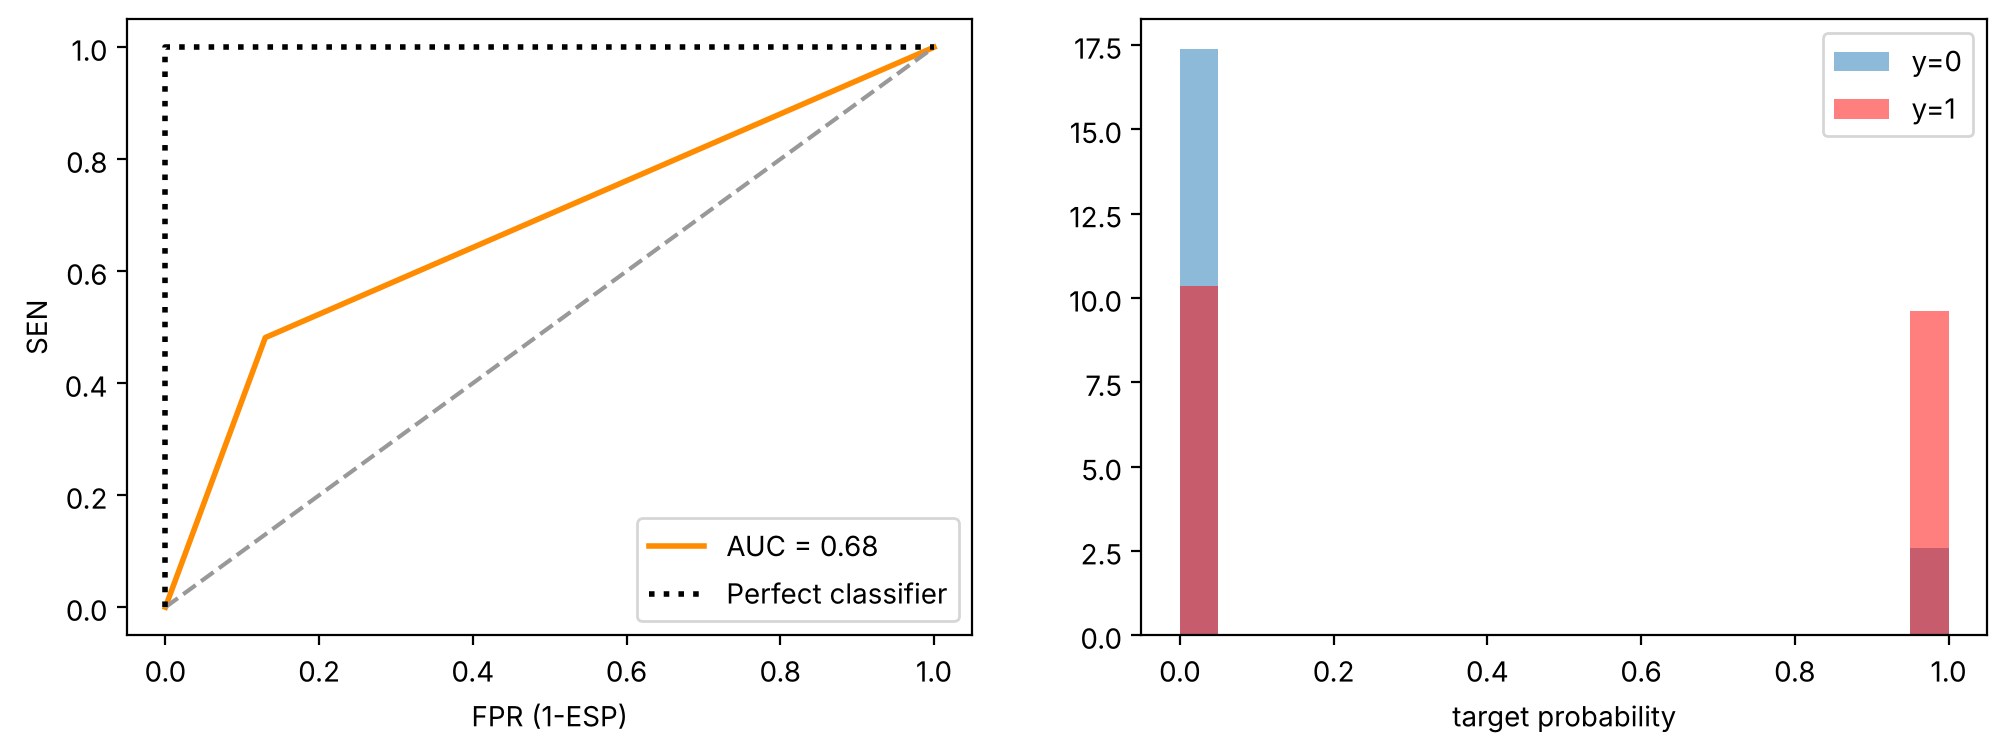

In [15]:
# And a fully grown tree (no restrictions at all): the typical overfitting
full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("Fully grown tree: depth =", full_tree.get_depth(), "| leaves =", full_tree.get_n_leaves())
analyze_train_test_performance(full_tree, X_train, X_test, y_train, y_test)

**Model selection.** If the CV is guided by **accuracy**, the best tree has `max_depth = 2` (CV accuracy 0.753), but accuracy rewards the majority class: in the depth table below (entropy, `min_samples_leaf = 30`) the trees of depth 1, 2 and 3 give *exactly* the same predictions (the new splits create leaves whose majority class is still "non-diabetic") and a test F1 of only 0.39. With the **F1 of the diabetic class** the best depth is 4 (the first tree that classifies a large group as diabetic: Age > 30.5 and Glucose > 107.5), and combining it with the other hyper-parameters the CV selects **entropy, `max_depth = 4`, `min_samples_leaf = 30`** (CV F1 = 0.653, 9 leaves). The hyper-parameter `min_samples_leaf` limits the depth indirectly: the larger it is, the fewer splits are allowed (a leaf cannot have fewer than 30 patients), so the tree is shallower and simpler.

**Does it overfit? Is it better than the baseline?** Chosen tree, train → test: accuracy 78.3 → 80.5 %, sensitivity 68.7 → 68.5 %, specificity 83.5 → 87.0 %, F1 68.9 → 71.2 %. There is **no overfitting** (the test result is even a bit better than the training one, which can only happen by chance in a small test set). It is also clearly better than the baseline in this split (accuracy 80.5 vs 71.4 %, F1 71.2 vs 56.0 %). **Caution:** this is partly luck of the partition; in the repeated cross-validation at the end the tree has F1 = 0.62 ± 0.06 and AUC 0.81, not better than logistic regression.

**What if we change max_depth?** Depth ≤ 3: too simple (test F1 0.39, *underfitting*). Depth 4: the best compromise. Larger depths: the test accuracy falls (0.773 for depth 5, 0.747 when it is unrestricted), the leaf-size restriction stops the tree at 15 leaves. A **fully grown tree** (no restrictions: depth 16, 114 leaves) has 100 % in training and 73.4 % in test (sensitivity 100 % → 48 %): the textbook case of **overfitting** (variance), which shows why a tree needs to be pruned (`max_depth` / `min_samples_leaf`).

## 2.3 DTs visualization

Trees can be visualized using the [`plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html#sklearn.tree.plot_tree) function

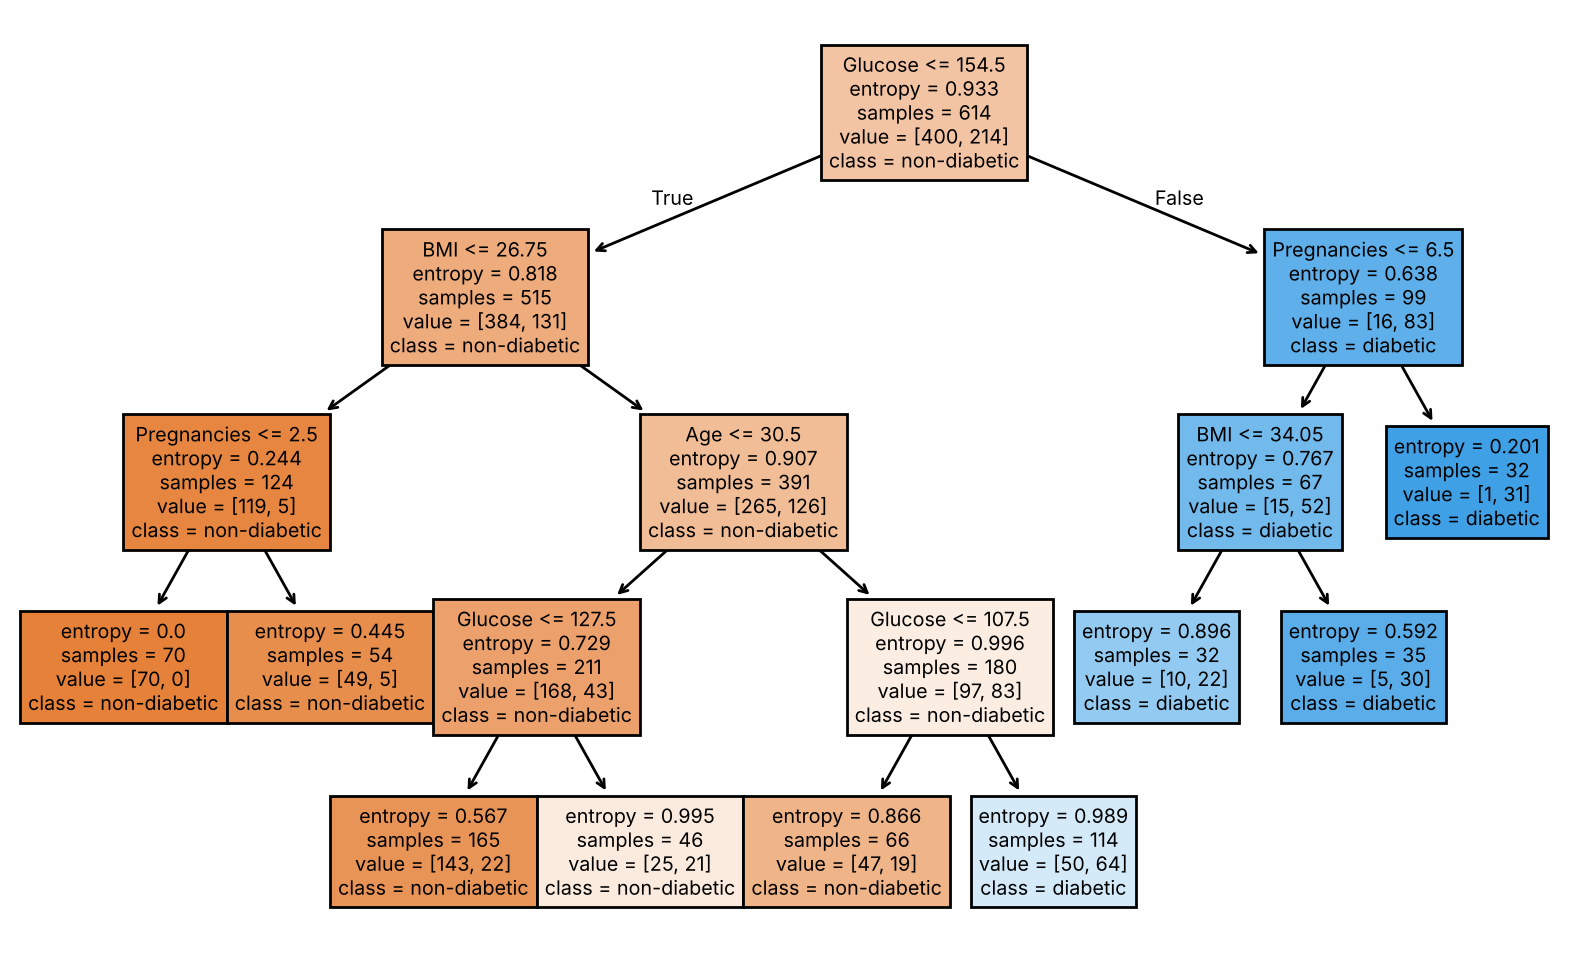

In [16]:
from sklearn.tree import plot_tree

# set plot dimensions
plt.figure(figsize=(10,6))

feature_names=df.columns.drop('Outcome')

plot_tree(
    dt_model,
    feature_names=feature_names, 
    class_names=['non-diabetic','diabetic'], 
    filled=True
)

plt.show()

## 2.4 Feature importance

In [17]:
# feature importance
def plot_importances(importances, feat_names):
    
    df_importances = pd.Series(importances, index=feat_names)
    
    plt.figure()
    df_importances.plot.bar()
    plt.ylabel("Feature Importance")
    plt.show()

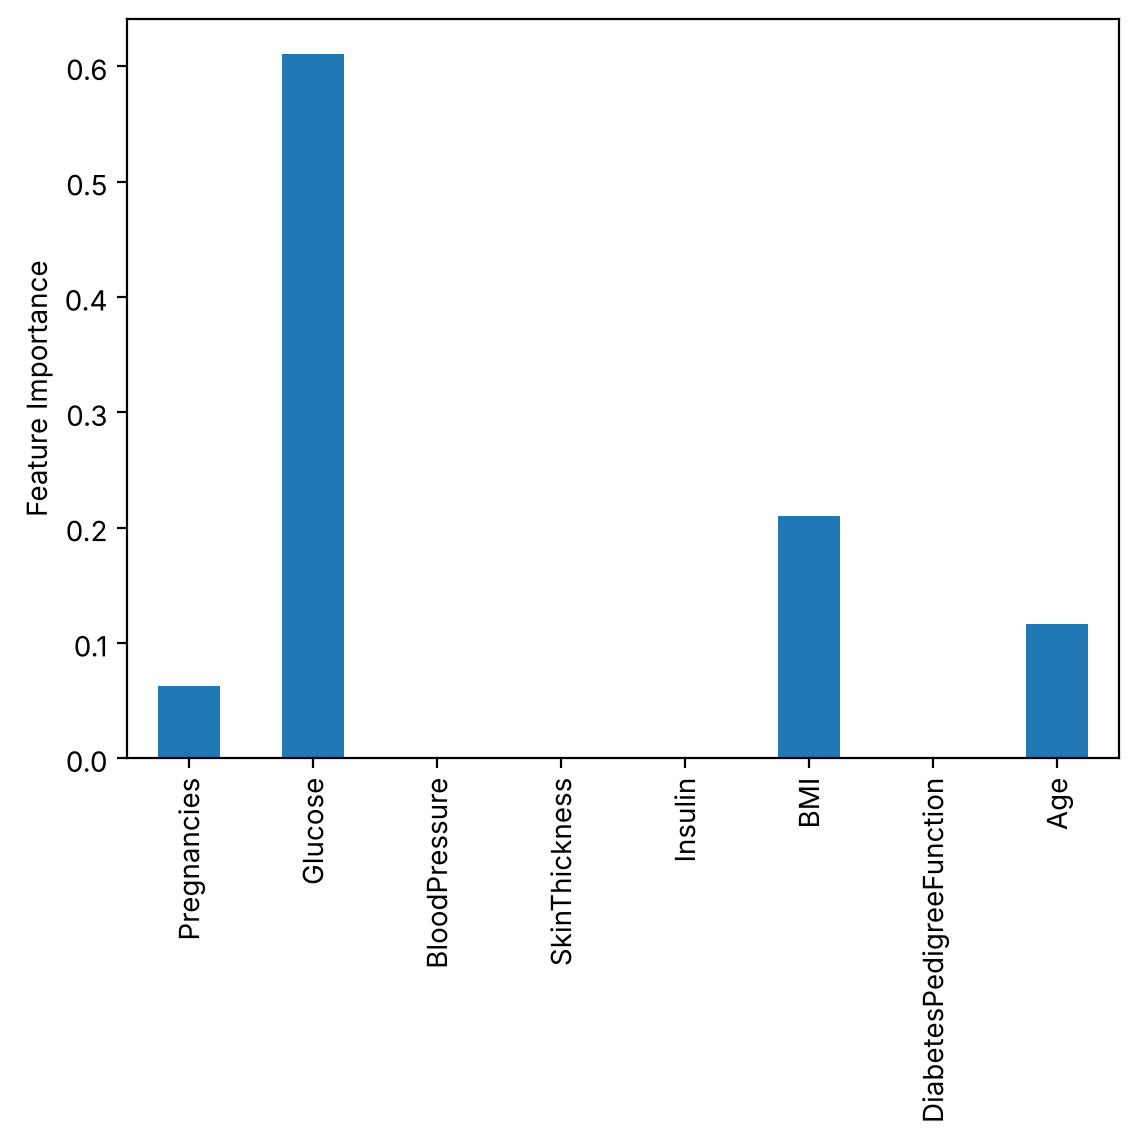

In [18]:
# Plot feature importance
plot_importances(dt_model.feature_importances_, feature_names)

In [19]:
# Text version of the rules of the chosen tree
from sklearn.tree import export_text
print(export_text(dt_model, feature_names=list(feature_names), show_weights=True))

|--- Glucose <= 154.50
|   |--- BMI <= 26.75
|   |   |--- Pregnancies <= 2.50
|   |   |   |--- weights: [70.00, 0.00] class: 0
|   |   |--- Pregnancies >  2.50
|   |   |   |--- weights: [49.00, 5.00] class: 0
|   |--- BMI >  26.75
|   |   |--- Age <= 30.50
|   |   |   |--- Glucose <= 127.50
|   |   |   |   |--- weights: [143.00, 22.00] class: 0
|   |   |   |--- Glucose >  127.50
|   |   |   |   |--- weights: [25.00, 21.00] class: 0
|   |   |--- Age >  30.50
|   |   |   |--- Glucose <= 107.50
|   |   |   |   |--- weights: [47.00, 19.00] class: 0
|   |   |   |--- Glucose >  107.50
|   |   |   |   |--- weights: [50.00, 64.00] class: 1
|--- Glucose >  154.50
|   |--- Pregnancies <= 6.50
|   |   |--- BMI <= 34.05
|   |   |   |--- weights: [10.00, 22.00] class: 1
|   |   |--- BMI >  34.05
|   |   |   |--- weights: [5.00, 30.00] class: 1
|   |--- Pregnancies >  6.50
|   |   |--- weights: [1.00, 31.00] class: 1



**Reading the tree.** The root question is **Glucose ≤ 154.5**:
* Glucose > 154.5 → diabetic in all the leaves, and the more pregnancies and the higher the BMI, the purer the leaf (e.g. Pregnancies > 6.5: 31 diabetic vs 1 non-diabetic).
* Glucose ≤ 154.5 and BMI ≤ 26.75 → almost all non-diabetic (70 vs 0 and 49 vs 5).
* Glucose ≤ 154.5, BMI > 26.75: young women (Age ≤ 30.5) are mostly non-diabetic; from 30.5 years on, those with Glucose > 107.5 are classified as diabetic (64 vs 50), the only "uncertain" leaf of the tree.

**Variable importance** (decrease of impurity): **Glucose 0.61, BMI 0.21, Age 0.12, Pregnancies 0.06**; the other four variables are never used (importance 0). This is **coherent with domain knowledge** (hyperglycaemia is the diagnostic criterion; obesity, age and number of pregnancies are classic risk factors for type 2 diabetes) and with the logistic regression of Lab 3 (Glucose ≫ BMI > Pregnancies, with DiabetesPedigreeFunction and Age behind). The difference (the tree uses Age and not DiabetesPedigreeFunction) shows that when variables are correlated the tree picks one of them by small differences in the data: trees are **unstable**, a small change in the training set can produce a different tree (the same limitation discussed in the Hoffmann et al. paper about decision trees for laboratory pathways), although they are easy to read and to validate with a clinician.

# 3. Random Forest (RF)

We are going to build a Random Forest Model and try to optimize the model by tuning max_depth

In [20]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest
param_grid = {'max_depth': range(1,5),
              'n_estimators' : [50,100,200,500,1000]}

# 3.1.Model selection ... this might take a while
grid_rf = hyper_parameters_search(RandomForestClassifier(random_state=0), X_train_norm, y_train, param_grid, scorer='f1')

best mean cross-validation score: 0.616
best parameters: {'max_depth': 4, 'n_estimators': 200}


PERFORMANCE METRICS
	TRAIN	TEST
ACC:	83.22	73.38
SEN:	62.15	50.00
ESP:	94.50	86.00
PPV:	85.81	65.85
F1:	72.09	56.84


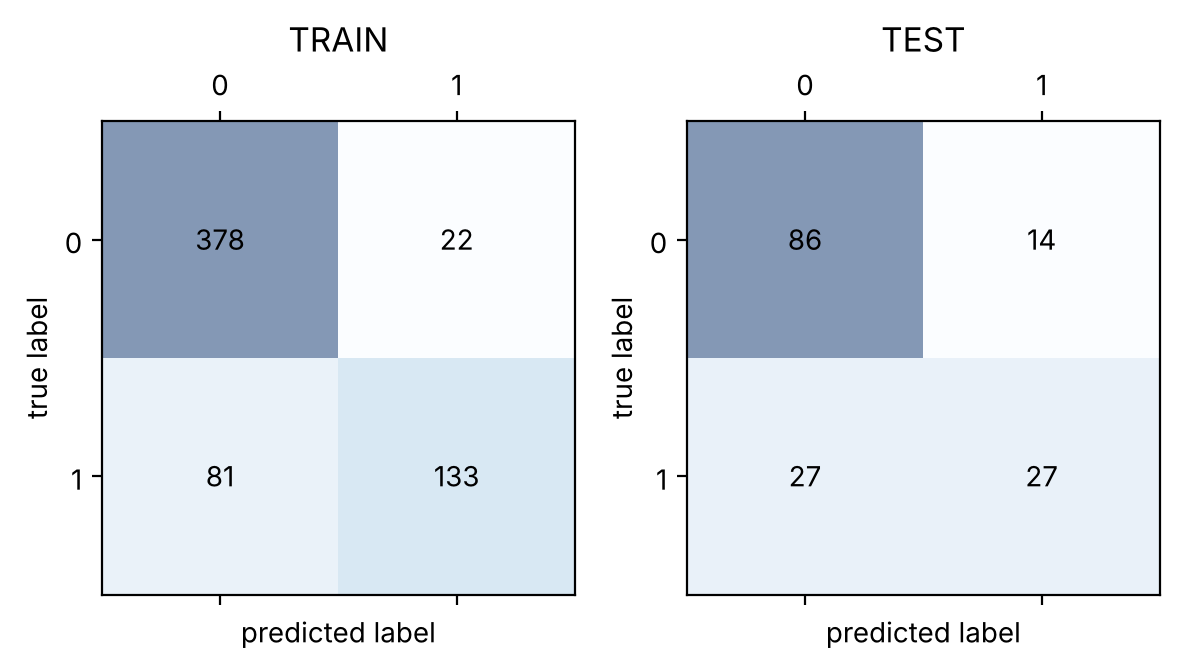

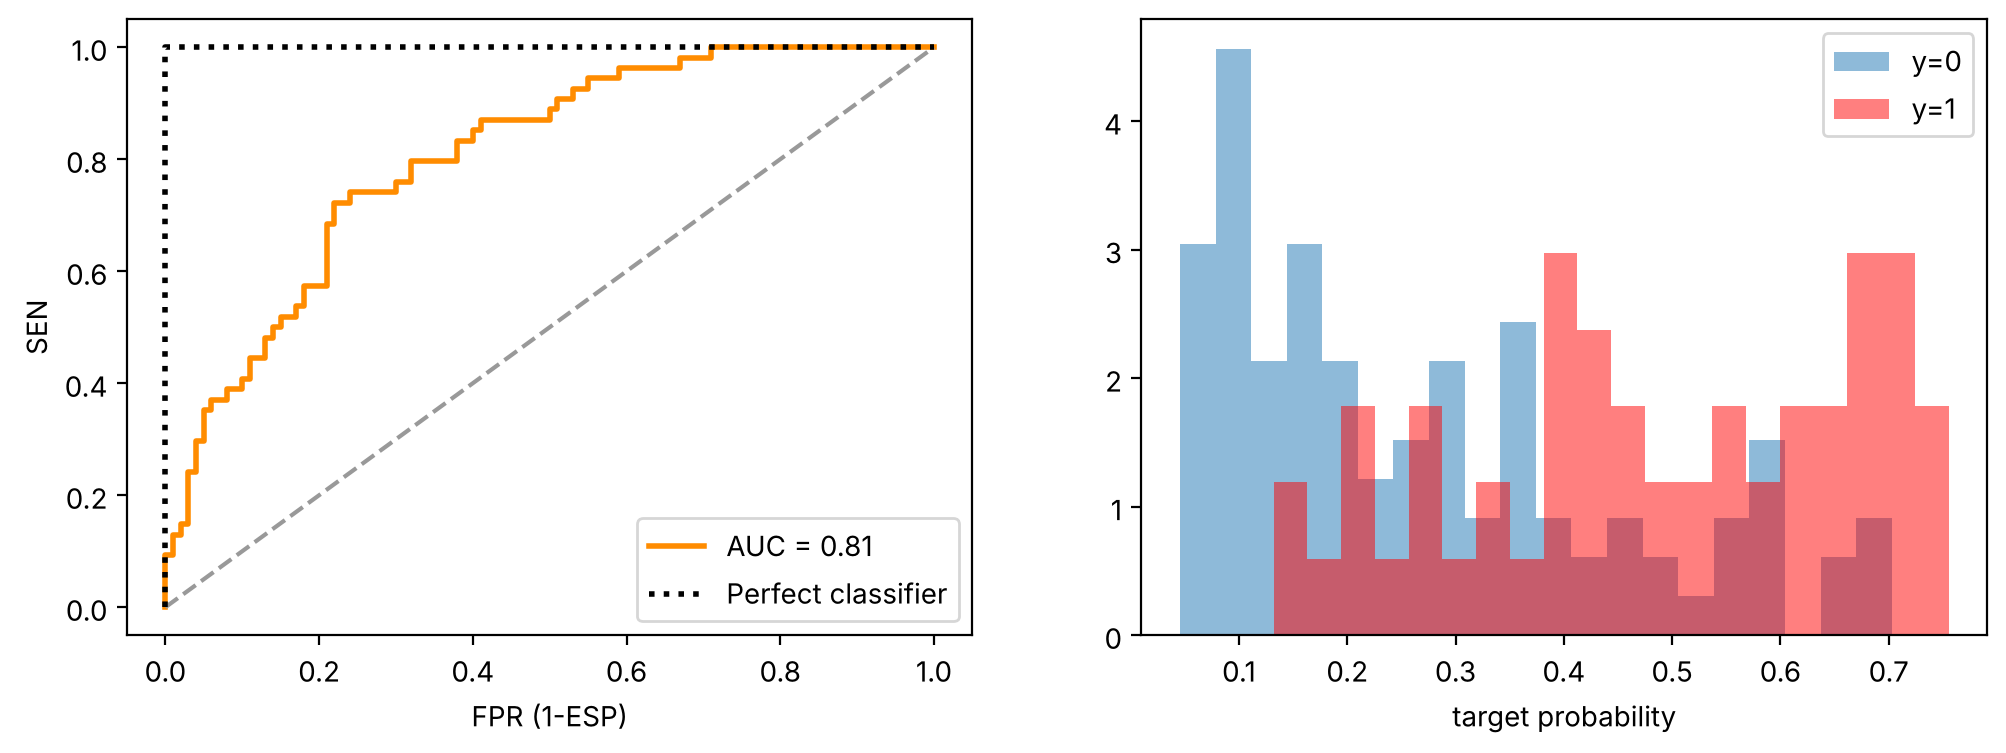

In [21]:
# 3.2 Evaluation

# your code here
# ...
rf_model =  RandomForestClassifier(random_state=0, **grid_rf.best_params_).fit(X_train_norm,y_train)
analyze_train_test_performance(rf_model,X_train_norm,X_test_norm,y_train,y_test)

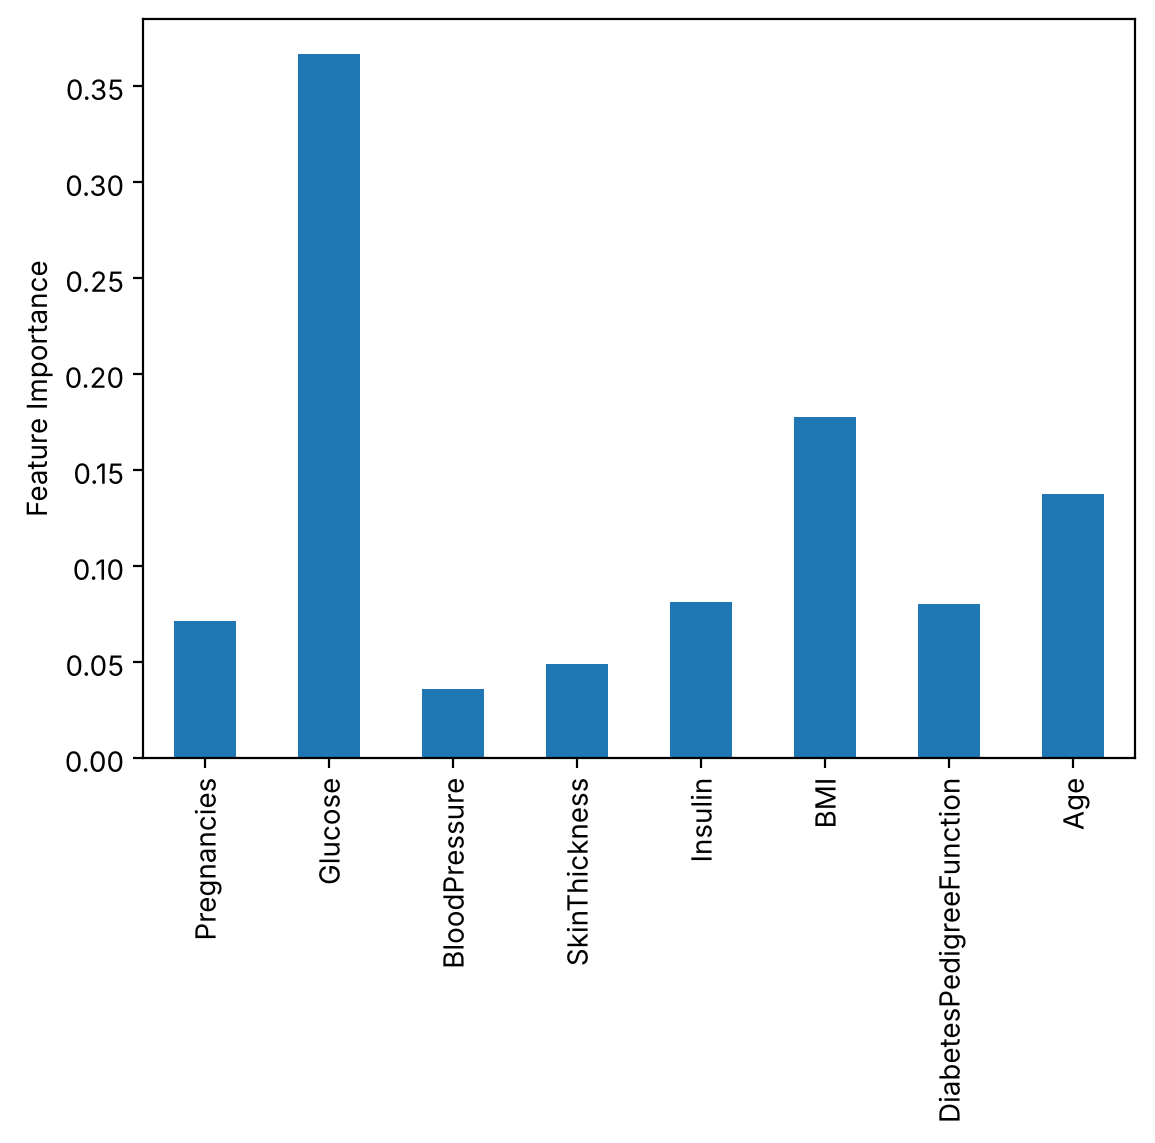

In [22]:
# 3.3 Feature importance

# your code here
# ...
plot_importances(rf_model.feature_importances_, feature_names)

In [23]:
# Another hyper-parameter along with max_depth, WITHOUT tuning n_estimators (fixed to 100): min_samples_leaf
param_grid2 = {'max_depth': range(1, 10), 'min_samples_leaf': [1, 3, 5, 10, 20]}
grid_rf2 = hyper_parameters_search(RandomForestClassifier(n_estimators=100, random_state=0), X_train_norm, y_train, param_grid2, scorer='f1')

# Once the two hyper-parameters are selected, increase the number of trees and compare on the test set
print("\nTest set, same max_depth / min_samples_leaf, different number of trees:")
for n in [100, 500, 2000]:
    m = RandomForestClassifier(n_estimators=n, random_state=0, **grid_rf2.best_params_).fit(X_train_norm, y_train)
    prob = m.predict_proba(X_test_norm)[:, 1]
    from sklearn.metrics import roc_auc_score
    print(f"n_estimators = {n:4d} | test F1 = {f1_score(y_test, m.predict(X_test_norm)):.3f} | test AUC = {roc_auc_score(y_test, prob):.3f} | test acc = {accuracy_score(y_test, m.predict(X_test_norm)):.3f}")

best mean cross-validation score: 0.642
best parameters: {'max_depth': 7, 'min_samples_leaf': 3}

Test set, same max_depth / min_samples_leaf, different number of trees:
n_estimators =  100 | test F1 = 0.594 | test AUC = 0.817 | test acc = 0.734


n_estimators =  500 | test F1 = 0.586 | test AUC = 0.813 | test acc = 0.734


n_estimators = 2000 | test F1 = 0.627 | test AUC = 0.814 | test acc = 0.753


<div class = "alert alert-success">

- Does this model overfit? 
- Is it better than our baseline?
- What are the most important features?
- Try another hyperparameter along with max_depth and without tuning n_estimators and once the two hyperparameters are selected increase the number of estimators. Is it better the performance?

</div>

**Random Forest.** The grid selects `max_depth = 4` and 200 trees (CV F1 = 0.616). Train → test: accuracy 83.2 → 73.4 %, sensitivity 62.2 → 50.0 %, F1 72.1 → 56.8 %: **there is overfitting** (gap of 10 points in accuracy and 15 in F1), although less than for a single full tree. **Better than the baseline?** Not clearly: accuracy 73.4 vs 71.4 %, but sensitivity 50.0 vs 51.9 %, F1 56.8 vs 56.0 % and AUC 0.805 vs 0.823.

**Most important features** (impurity-based importance): Glucose (0.37), BMI (0.18), Age (0.14), followed by Insulin, DiabetesPedigreeFunction and Pregnancies (0.07–0.08). The forest spreads the importance over more variables than the single tree; note that the impurity importance is biased in favour of continuous variables with many different values (Insulin, SkinThickness), which receive some importance even when their permutation importance is ≈ 0 (see Section 6).

**Another hyper-parameter, then more trees.** Tuning `max_depth` together with `min_samples_leaf` (with 100 trees) gives `max_depth = 7`, `min_samples_leaf = 3` (CV F1 = 0.642, better than 0.616). Increasing the number of trees with those values does **not** improve the test performance in a systematic way (AUC 0.817 → 0.813 → 0.814, F1 0.594 → 0.586 → 0.627 for 100, 500 and 2000 trees; the changes are a couple of patients).

*Theory.* A Random Forest is a **bagging** ensemble: each tree is trained on a bootstrap sample and, at each split, with a random subset of the variables; the final output is the average of the trees. Averaging decorrelated deep trees **reduces the variance** without increasing the bias. The variance reduction saturates after a few hundred trees, and adding trees never causes overfitting (it only costs time), which is why the number of trees is not a critical hyper-parameter, whereas the depth / leaf size (complexity of each tree) is.

# 4. Gradient Boosting (trees) (BT)

In [24]:
from sklearn.ensemble import GradientBoostingClassifier

param_grid = {
    'n_estimators' : [50,100,200,500],#, 1000, 2000],
    'learning_rate': [0.1,0.05,0.01, 0.005, 0.001],
    'max_depth': [1, 2]
}

# 4.1 Model selection ... this might take a while
grid_bt = hyper_parameters_search(GradientBoostingClassifier(random_state=0), X_train_norm, y_train, param_grid, scorer='f1')

best mean cross-validation score: 0.622
best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}


PERFORMANCE METRICS
	TRAIN	TEST
ACC:	85.99	73.38
SEN:	71.03	55.56
ESP:	94.00	83.00
PPV:	86.36	63.83
F1:	77.95	59.41


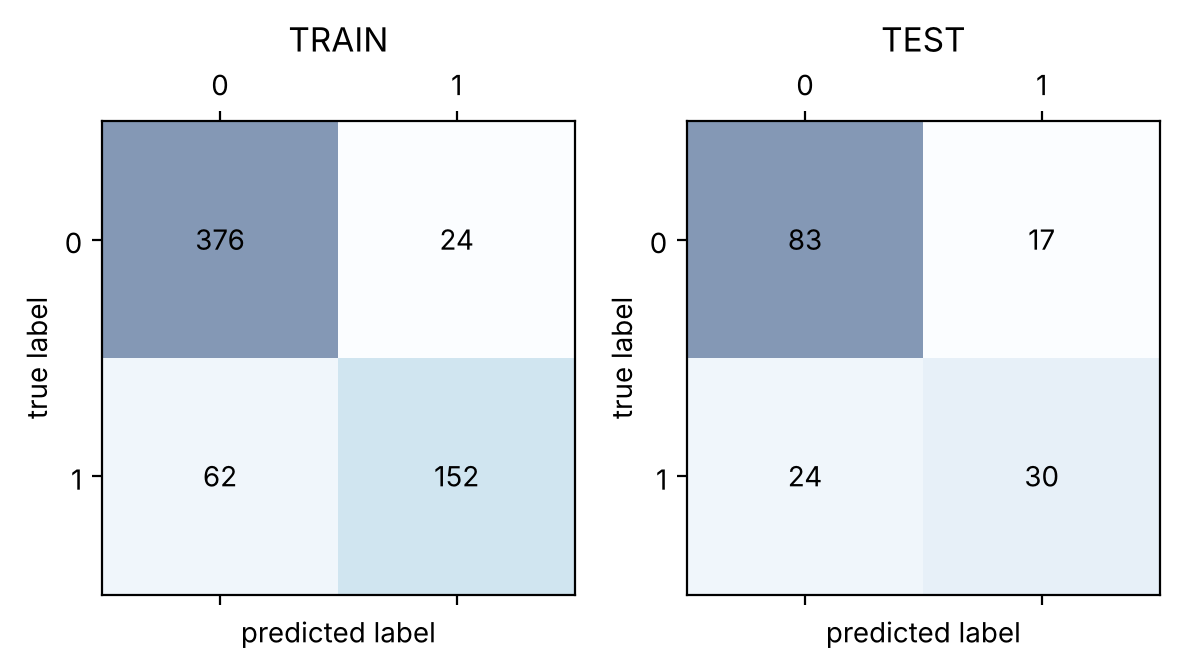

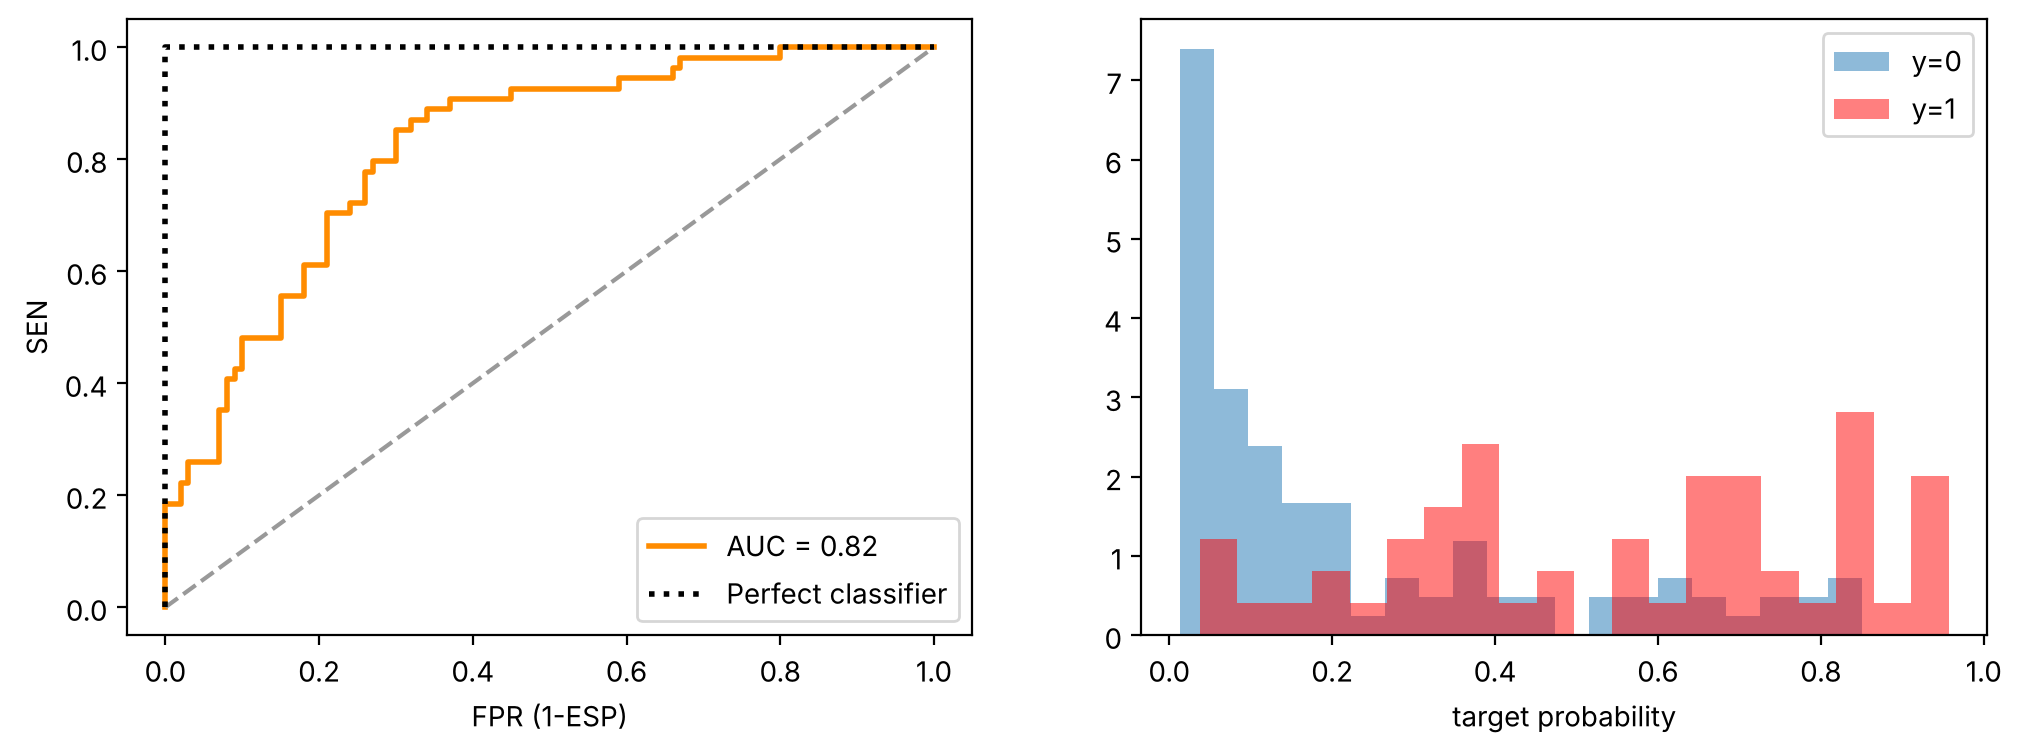

In [25]:
# 4.2 Model evaluation

# your code here
#  ...

bt_model =  GradientBoostingClassifier(random_state=0, **grid_bt.best_params_).fit(X_train_norm,y_train)
analyze_train_test_performance(bt_model,X_train_norm,X_test_norm,y_train,y_test)



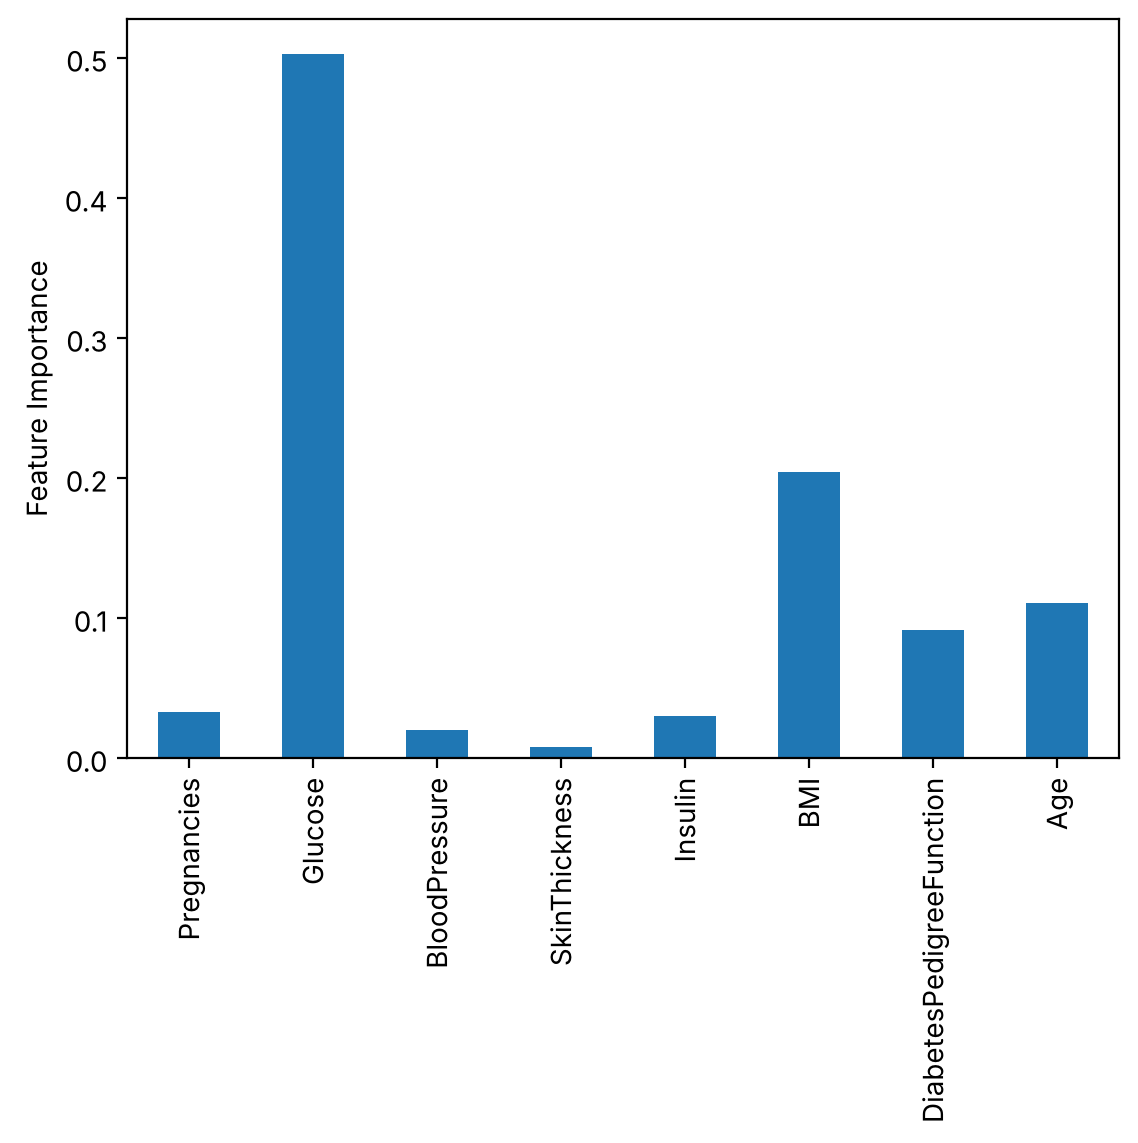

In [26]:
# 4.3 Feature importance

# your code here
# ...
plot_importances(bt_model.feature_importances_, feature_names)

<div class = "alert alert-success">

- Does this model overfit? 
- Is it better than our baseline?
- What are the most important features?

</div>

**Gradient Boosting.** The grid selects `learning_rate = 0.1`, `max_depth = 2`, `n_estimators = 100` (CV F1 = 0.622). Train → test: accuracy 86.0 → 73.4 %, sensitivity 71.0 → 55.6 %, F1 77.9 → 59.4 %: **it is the model that overfits the most** (gap of 12.6 points in accuracy and 18.5 in F1). Compared with the baseline: accuracy 73.4 vs 71.4 %, sensitivity 55.6 vs 51.9 %, F1 59.4 vs 56.0 % and the same AUC (0.821 vs 0.823), so there is **no clear gain** with respect to the logistic regression.

**Most important features:** Glucose (0.50), BMI (0.20), Age (0.11) and DiabetesPedigreeFunction (0.09); BloodPressure, SkinThickness and Insulin are almost irrelevant (≤ 0.03).

*Theory.* **Boosting** builds the ensemble sequentially: each new (shallow, "weak") tree is fitted to the errors (the negative gradient of the loss) of the current ensemble, and it is added with a weight `learning_rate`. It mainly reduces the **bias** and, unlike bagging, adding more trees *can* overfit; that is why `learning_rate` (shrinkage), `n_estimators` and `max_depth` are tuned together (small learning rate → more trees are needed).

# 5. Multilayer Perceptron (MLP)

We are going to build a MLP with 
* 1 hidden layer 5 units
* 1 hidden layer 10 units
* 2 hidden layers 5 units.


In [27]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPClassifier

param_grid = {
    'alpha' : 10.0 ** -np.arange(1, 7), # following recommendation: https://scikit-learn.org/stable/modules/neural_networks_supervised.html#tips-on-practical-use
    'hidden_layer_sizes': [(5,), (10,), (5, 5)]   # 1 hidden layer 5 units, 1 hidden layer 10 units, 2 hidden layers 5 units
}

# 5.1 Model selection (alpha = L2 regularization of the weights). max_iter large enough to converge
grid_mlp = hyper_parameters_search(MLPClassifier(random_state=0, max_iter=2000), X_train_norm, y_train, param_grid, scorer='f1')

best mean cross-validation score: 0.679
best parameters: {'alpha': np.float64(0.01), 'hidden_layer_sizes': (5, 5)}


Chosen hyper-parameters: {'alpha': np.float64(0.01), 'hidden_layer_sizes': (5, 5)}
PERFORMANCE METRICS
	TRAIN	TEST
ACC:	79.32	72.73
SEN:	68.69	57.41
ESP:	85.00	81.00
PPV:	71.01	62.00
F1:	69.83	59.62


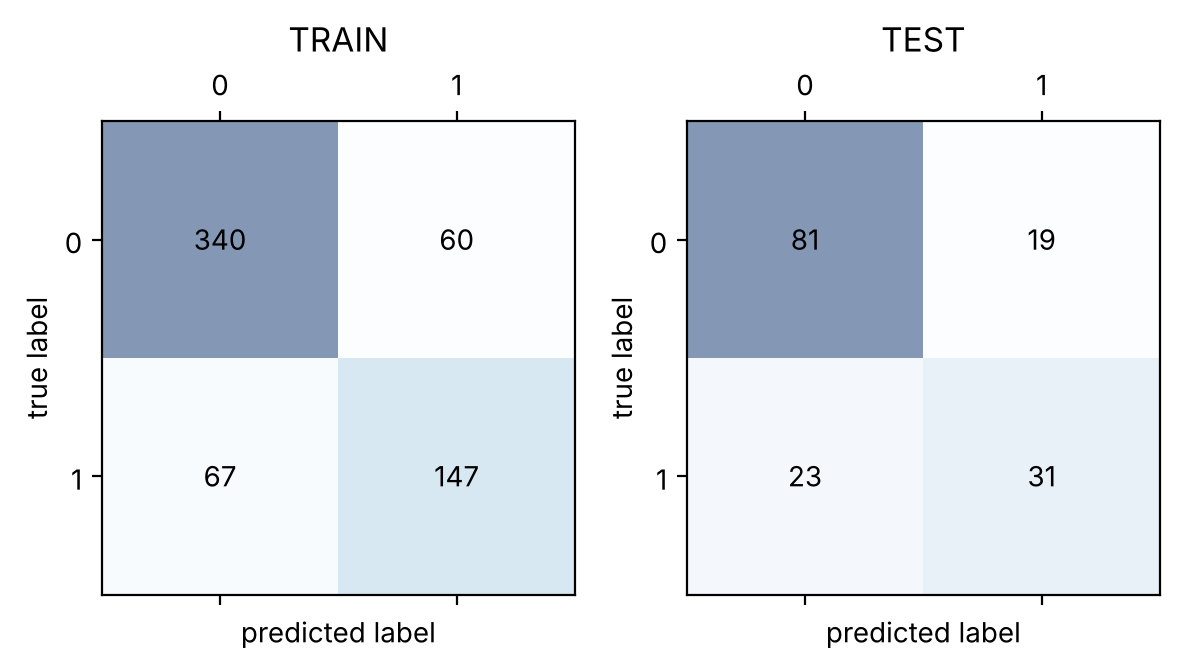

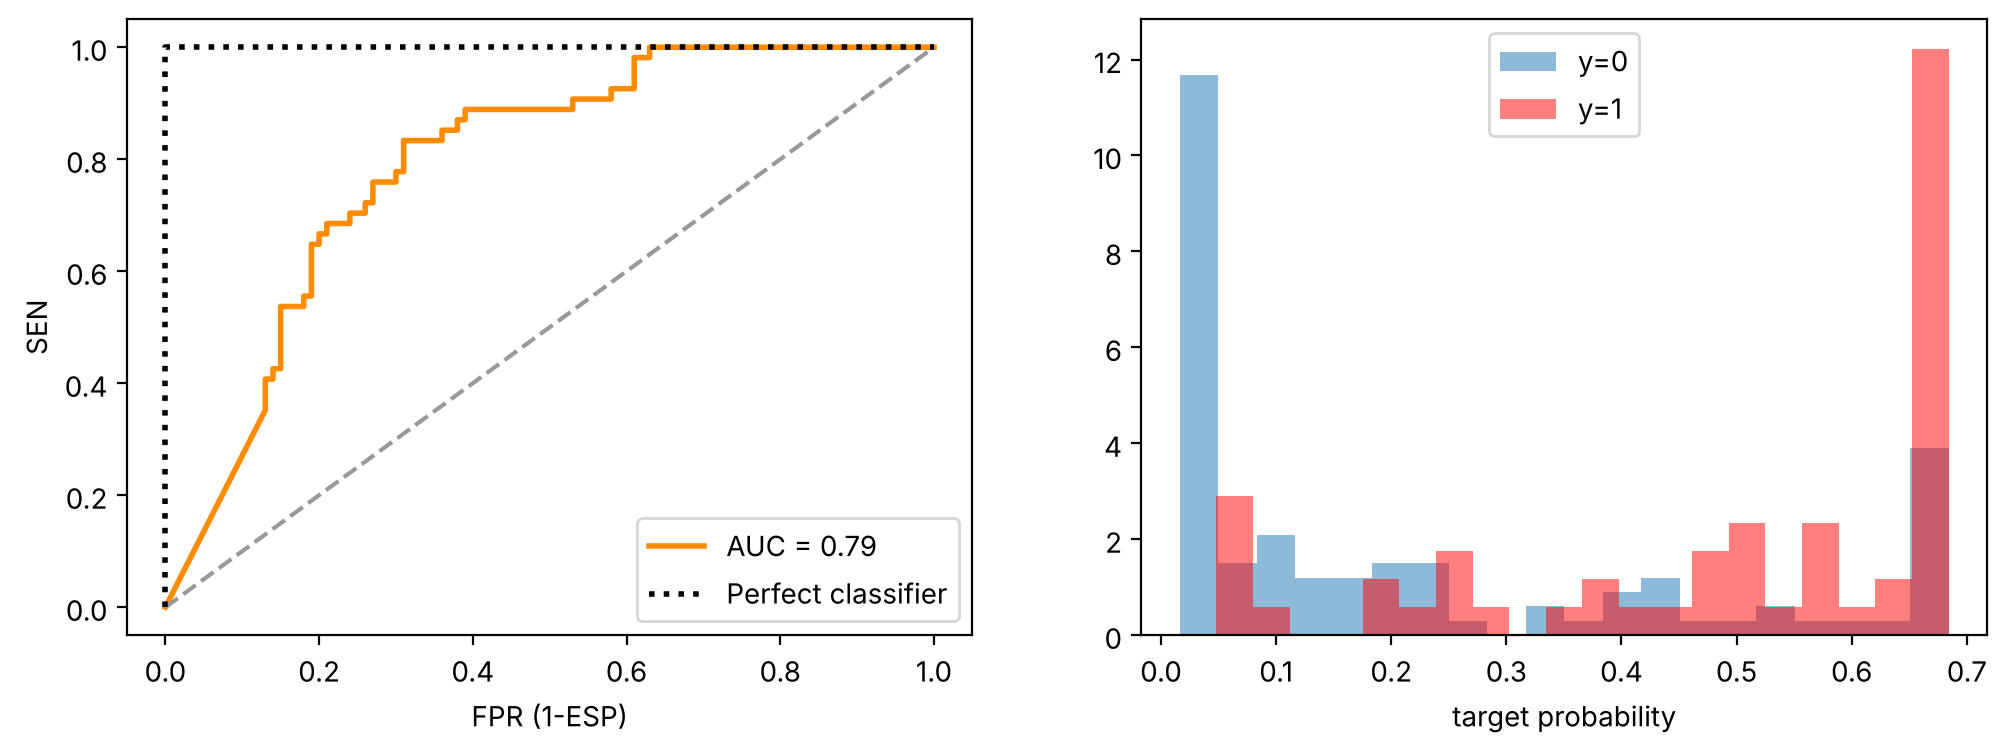

In [28]:
# 5.2 Model evaluation
mlp_model =  MLPClassifier(random_state=0, max_iter=2000, **grid_mlp.best_params_).fit(X_train_norm,y_train)
print("Chosen hyper-parameters:", grid_mlp.best_params_)
analyze_train_test_performance(mlp_model,X_train_norm,X_test_norm,y_train,y_test)

<div class = "alert alert-success">

- Does this model overfit? 
- Is it better than our baseline?
- What are the most important features?

</div>

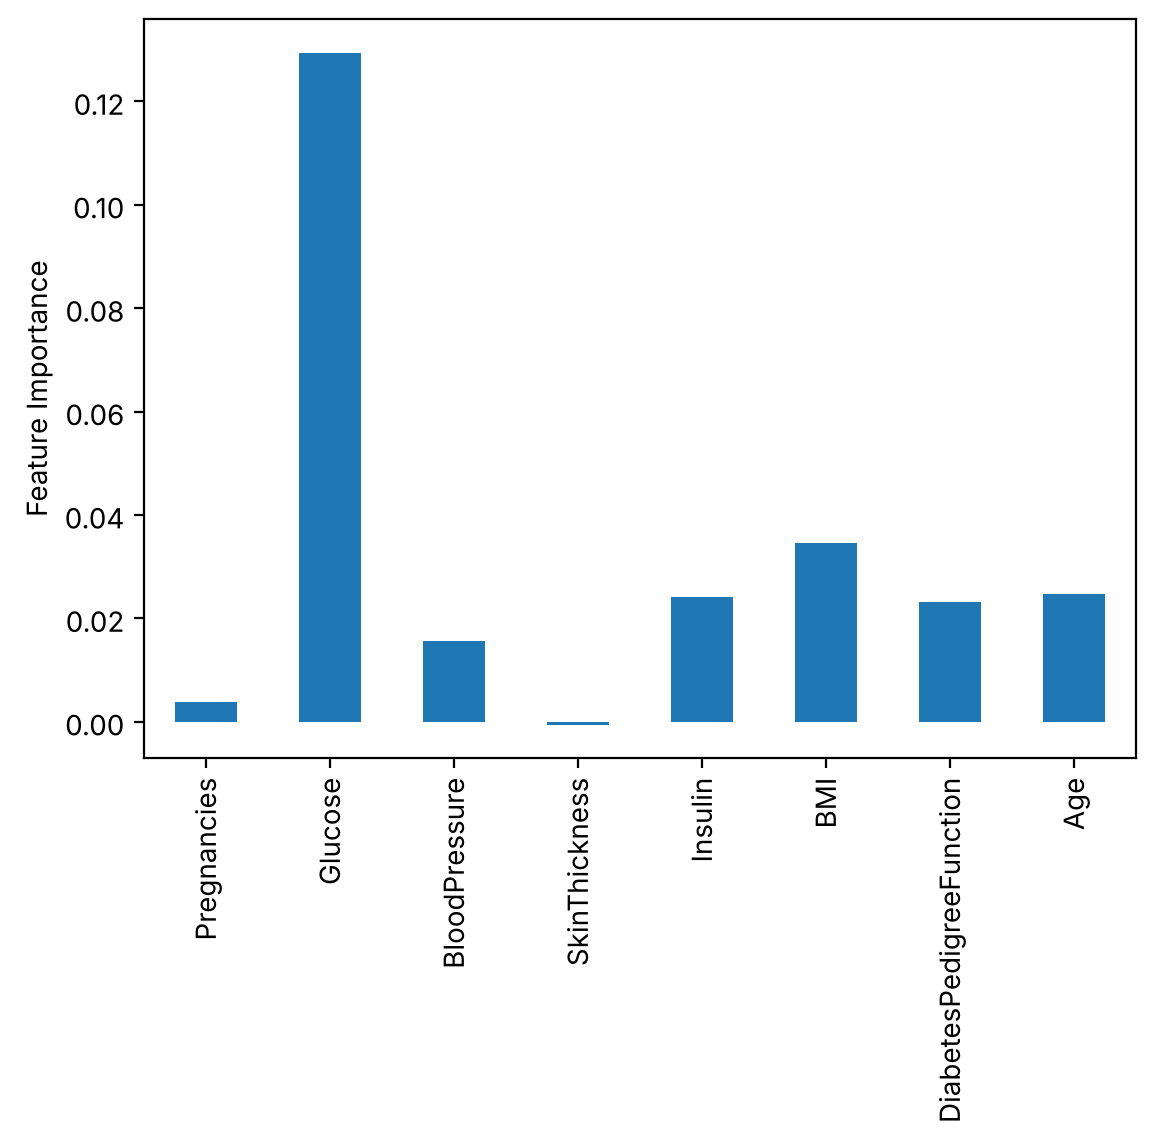

In [29]:
# An MLP has no built-in feature importance. We use permutation importance on the test set (model-agnostic):
# shuffle one variable at a time and measure how much the AUC drops
from sklearn.inspection import permutation_importance
perm = permutation_importance(mlp_model, X_test_norm, y_test, scoring='roc_auc', n_repeats=30, random_state=0)
plot_importances(perm.importances_mean, feature_names)

**MLP.** The grid selects 2 hidden layers of 5 units and `alpha = 0.01` (CV F1 = 0.679, the highest validation F1 of all the models). Train → test: accuracy 79.3 → 72.7 %, sensitivity 68.7 → 57.4 %, F1 69.8 → 59.6 %: moderate overfitting (7 points of accuracy, 10 of F1), which is controlled by the L2 penalty `alpha` and the small number of units. **Better than the baseline?** Marginally on the hard metrics (accuracy 72.7 vs 71.4 %, sensitivity 57.4 vs 51.9 %, F1 59.6 vs 56.0 %), worse in AUC (0.793 vs 0.823). The extra flexibility of a neural network (non-linear combination of the variables) does not pay off: with ~600 training patients and a relationship that is almost linear, the logistic regression is just as good, with far fewer parameters.

**Most important features.** An MLP does not provide importances by itself: with the permutation importance on the test set (drop of the AUC when a variable is shuffled), the order is Glucose (0.129) ≫ BMI (0.035) > Age (0.025) ≈ Insulin (0.024) ≈ DiabetesPedigreeFunction (0.023), in agreement with the tree-based models.

# 6. Model comparison

If you have done all of the above, just run the following cell

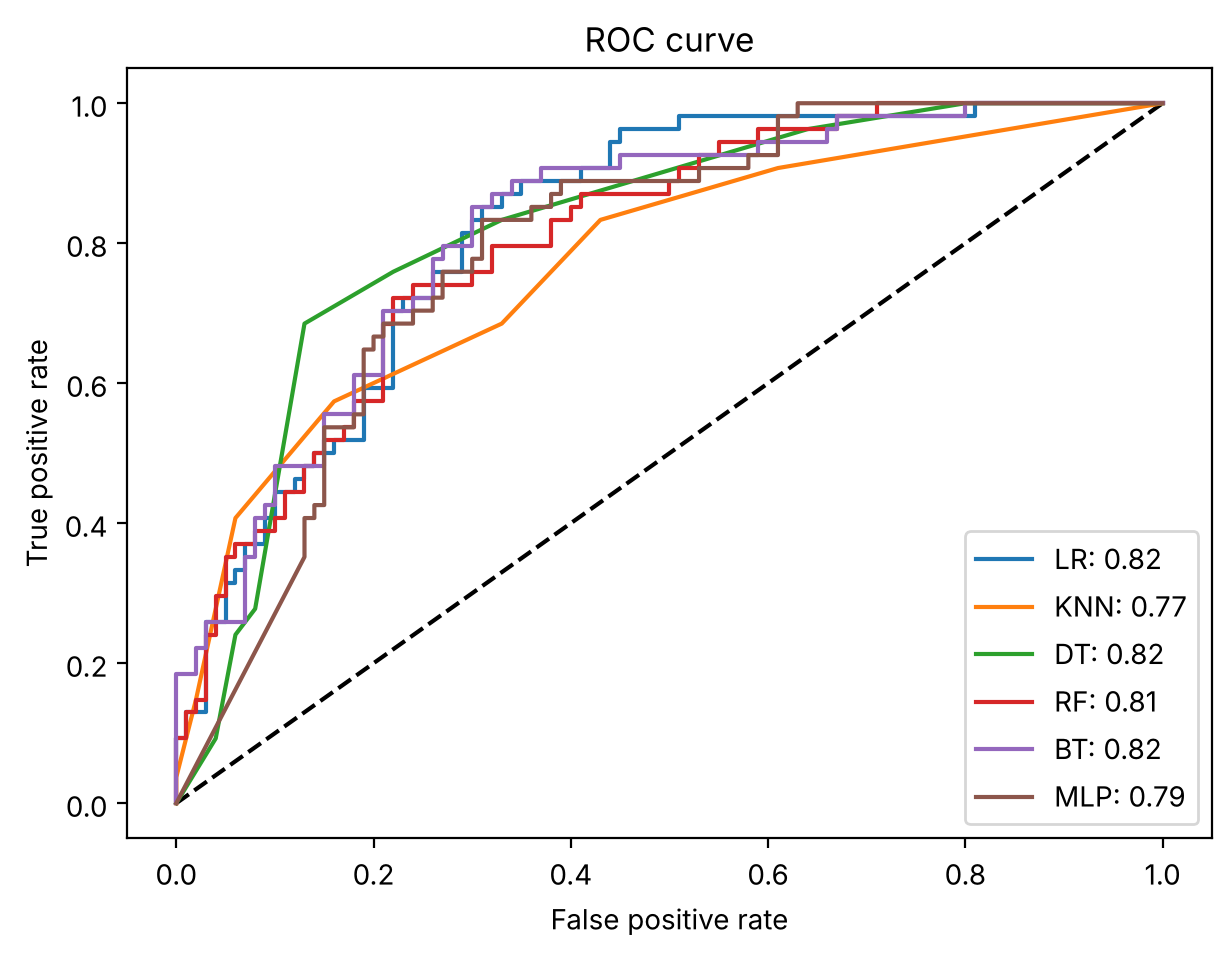

,ACC,SEN,ESP,PPV,F1,AUC
model,,,,,,
LR,0.714,0.519,0.82,0.609,0.560,0.823
KNN,0.747,0.574,0.84,0.660,0.614,0.774
DT,0.805,0.685,0.87,0.740,0.712,0.822
RF,0.734,0.500,0.86,0.659,0.568,0.805
BT,0.734,0.556,0.83,0.638,0.594,0.821
MLP,0.727,0.574,0.81,0.620,0.596,0.793


In [30]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from src.utils import get_metrics
from sklearn.metrics import confusion_matrix

# NOTE: the template used the k-NN model for 'DT' and the normalized test set for every model. The tree was trained with
# the non-normalized variables, so each model must be evaluated on the version of the data it was trained with.
modelos = {'LR': (lr_model, X_test_norm), 'KNN': (knn_model, X_test_norm), 'DT': (dt_model, X_test),
           'RF': (rf_model, X_test_norm), 'BT': (bt_model, X_test_norm), 'MLP': (mlp_model, X_test_norm)}

plt.figure(figsize=(7,5))
plt.plot([0, 1], [0, 1], 'k--')
rows = []
for k, (model, Xte) in modelos.items():
    prob = model.predict_proba(Xte)[:,1]
    fpr, tpr,_ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label = k + ': %0.2f' % roc_auc)
    acc, sen, esp, ppv, fsc = get_metrics(confusion_matrix(y_test, model.predict(Xte)))
    rows.append({'model': k, 'ACC': acc, 'SEN': sen, 'ESP': esp, 'PPV': ppv, 'F1': fsc, 'AUC': roc_auc})

plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend(loc="lower right")
plt.show()

pd.DataFrame(rows).set_index('model').round(3)

In [31]:
# The test set has only 154 patients, so a single split is noisy. Repeated stratified 5-fold CV (5 x 5 = 25 evaluations) of
# the whole procedure with the chosen hyper-parameters on ALL the data gives a mean and a standard deviation of the AUC / F1
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

final_models = {
    'LR':  make_pipeline(StandardScaler(), LogisticRegression()),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(**grid_knn.best_params_)),
    'DT':  DecisionTreeClassifier(random_state=0, **grid_dt_full.best_params_),
    'RF':  make_pipeline(StandardScaler(), RandomForestClassifier(random_state=0, **grid_rf.best_params_)),
    'BT':  make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=0, **grid_bt.best_params_)),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(random_state=0, max_iter=2000, **grid_mlp.best_params_)),
}
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
rows = []
for name, model in final_models.items():
    cv = cross_validate(model, X, y, cv=rskf, scoring=['roc_auc', 'f1', 'accuracy', 'recall'])
    rows.append({'model': name, 'AUC mean': cv['test_roc_auc'].mean(), 'AUC std': cv['test_roc_auc'].std(),
                 'F1 mean': cv['test_f1'].mean(), 'F1 std': cv['test_f1'].std(),
                 'ACC mean': cv['test_accuracy'].mean(), 'SEN mean': cv['test_recall'].mean()})
cv_table = pd.DataFrame(rows).set_index('model')
cv_table.round(3)

,AUC mean,AUC std,F1 mean,F1 std,ACC mean,SEN mean
model,,,,,,
LR,0.832,0.036,0.642,0.041,0.777,0.575
KNN,0.784,0.034,0.600,0.044,0.745,0.550
DT,0.813,0.031,0.620,0.062,0.750,0.599
RF,0.835,0.030,0.614,0.043,0.769,0.528
BT,0.834,0.034,0.632,0.051,0.763,0.584
MLP,0.813,0.034,0.640,0.052,0.749,0.642


,LR,KNN,DT,RF,BT,MLP
Pregnancies,0.031,0.015,0.003,0.012,0.012,0.004
Glucose,0.174,0.107,0.140,0.106,0.127,0.129
BloodPressure,0.013,0.016,0.000,-0.002,0.003,0.016
SkinThickness,-0.004,-0.012,0.000,-0.002,-0.001,-0.001
Insulin,0.006,0.037,0.000,0.005,0.006,0.024
BMI,0.040,0.049,0.115,0.042,0.055,0.035
DiabetesPedigreeFunction,0.011,0.037,0.000,0.007,0.011,0.023
Age,0.006,0.032,0.056,0.029,0.021,0.025


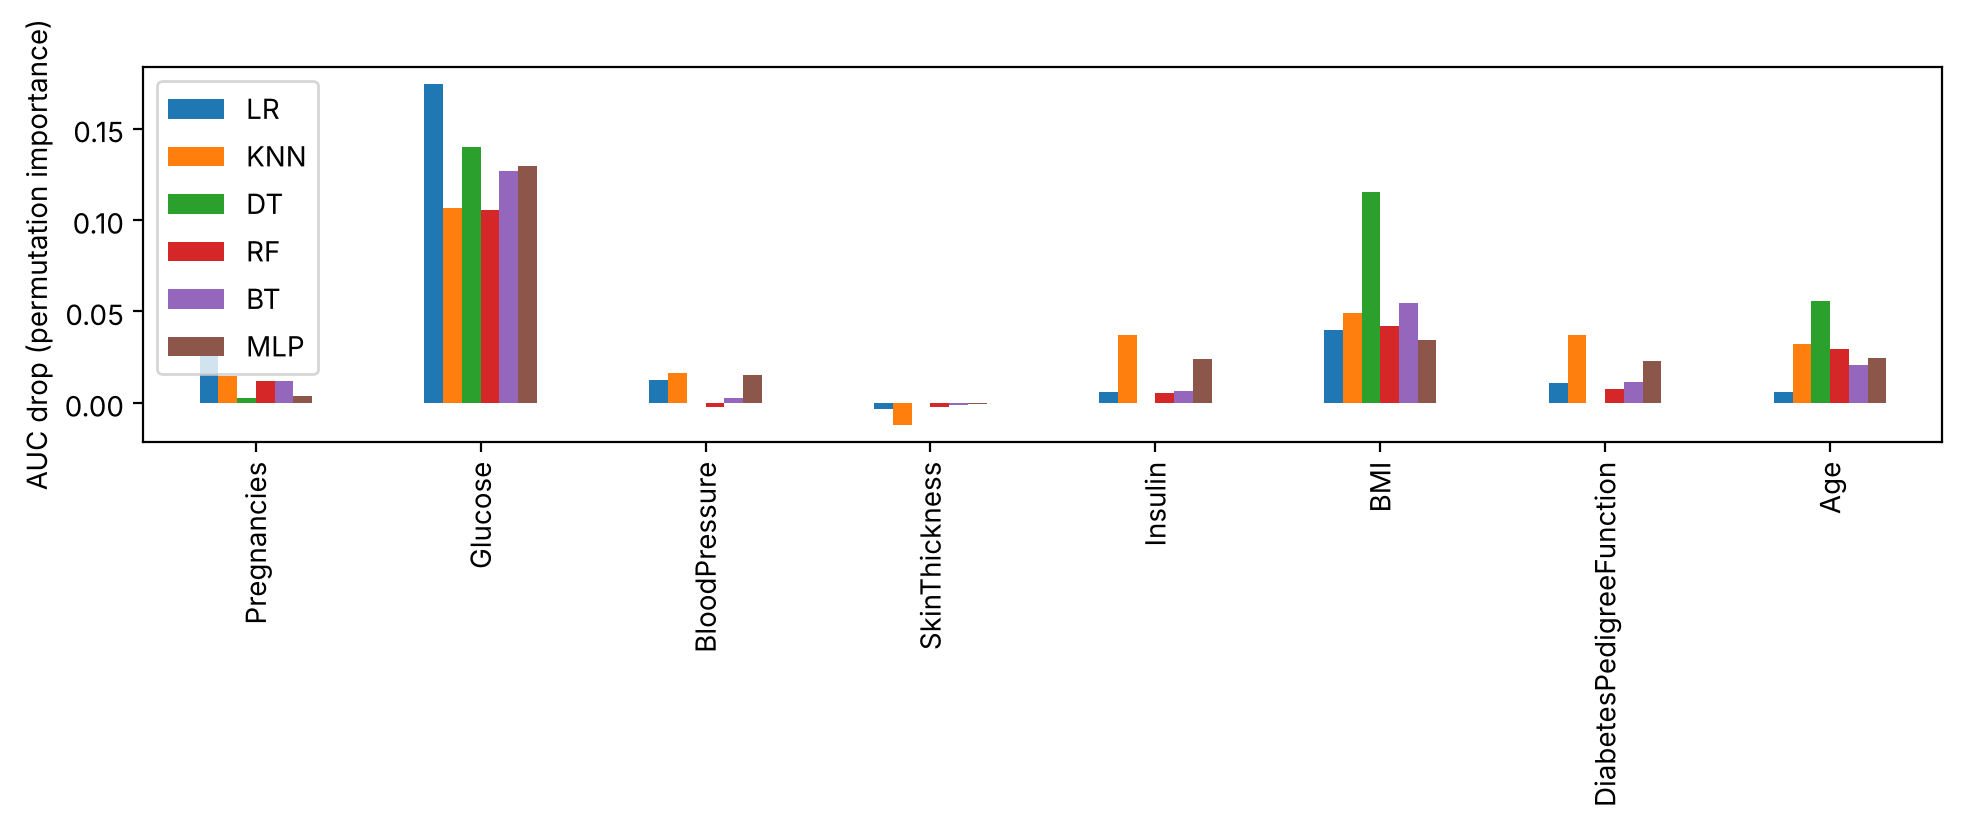

In [32]:
# Which are the most important features for each model? Permutation importance on the test set (drop of AUC when a variable is shuffled)
imp = {}
for k, (model, Xte) in modelos.items():
    p = permutation_importance(model, Xte, y_test, scoring='roc_auc', n_repeats=30, random_state=0)
    imp[k] = p.importances_mean
imp = pd.DataFrame(imp, index=feature_names)
display(imp.round(3))
imp.plot(kind='bar', figsize=(10, 4)); plt.ylabel('AUC drop (permutation importance)'); plt.tight_layout(); plt.show()

<div class = "alert alert-success">

Taking into account the above results, in your opinion
    
- What is the best model? Justify your answer 
- And the most important feature(s)? 
- If you want to improve these results, what would you do?

</div>

In [33]:
# What can we do to improve the results? In Lab 1 we saw that the zeros of Glucose, BloodPressure, SkinThickness, Insulin and BMI
# are missing values. Here the data are raw. We replace them with NaN and impute with the MEDIAN of the training folds
# (the imputer is inside the pipeline -> it is fitted only with the training data of each fold: no leakage)
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer

zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
def zeros_to_nan(data):
    data = data.copy()
    data[zero_cols] = data[zero_cols].replace(0, np.nan)
    return data

rows = []
for name, model in final_models.items():
    steps = list(model.steps) if hasattr(model, 'steps') else [('model', model)]
    model_imp = make_pipeline(FunctionTransformer(zeros_to_nan), SimpleImputer(strategy='median'), *[s[1] for s in steps])
    cv = cross_validate(model_imp, X, y, cv=rskf, scoring=['roc_auc', 'f1'])
    rows.append({'model': name, 'AUC raw': cv_table.loc[name, 'AUC mean'], 'AUC imputed': cv['test_roc_auc'].mean(),
                 'F1 raw': cv_table.loc[name, 'F1 mean'], 'F1 imputed': cv['test_f1'].mean()})
pd.DataFrame(rows).set_index('model').round(3)

,AUC raw,AUC imputed,F1 raw,F1 imputed
model,,,,
LR,0.832,0.837,0.642,0.628
KNN,0.784,0.806,0.600,0.614
DT,0.813,0.815,0.620,0.616
RF,0.835,0.839,0.614,0.609
BT,0.834,0.834,0.632,0.634
MLP,0.813,0.810,0.640,0.635


**What is the best model?** On this *single* test set the decision tree is the best (accuracy 80.5 %, F1 0.71, sensitivity 68.5 %), followed by k-NN, BT, RF and MLP (accuracy 73–75 %), and logistic regression (71.4 %). But the test set has 154 patients (54 diabetic), so one split is noisy. The **repeated 5×5 cross-validation** on all the data with the chosen hyper-parameters (table above) gives the more reliable picture: AUC = **RF 0.835, BT 0.834, LR 0.832** (std ≈ 0.03–0.036), DT 0.813, MLP 0.813 and **k-NN 0.784** (the worst); F1 between 0.60 (k-NN) and 0.64 (LR, MLP), with std 0.04–0.06. The differences among LR, RF and BT (≤ 0.003 in AUC) are 10 times smaller than the standard deviation, so they cannot be distinguished; the tree's brilliant test result was luck of the partition (its CV F1 is 0.62 ± 0.06). In summary: **no non-parametric method clearly beats the logistic regression baseline**. My choice would be the **logistic regression** (simplest, interpretable, well-calibrated probabilities, AUC ≈ 0.83) and, if a small gain in ranking is needed, RF or BT; if the goal is to give clinicians explicit rules, the depth-4 tree.

**Most important features.** For the six models, **Glucose is by far the first** (permutation importance 0.11–0.17 of AUC), followed by **BMI** (0.04–0.12) and then, depending on the model, Age, Pregnancies, Insulin and DiabetesPedigreeFunction; **BloodPressure and SkinThickness** have importance ≈ 0. It agrees with the clinical knowledge and with Lab 3.

**How to improve the results?** (1) **Treat the zeros as missing values** (Glucose 5, BloodPressure 35, SkinThickness 227, Insulin 374, BMI 11 zeros): imputing them with the median *inside* the pipeline raises the CV AUC of k-NN from 0.784 to 0.806 (the zeros distort the distances), LR from 0.832 to 0.837 and RF from 0.835 to 0.839, with practically no change (±0.003) for the others (F1 changes by ±0.015, which is noise): a modest but free gain. (2) Move the **decision threshold** (or use `class_weight='balanced'` / resampling only in the training folds) to increase the sensitivity, which is low (50–69 %) for every model. (3) Feature engineering (e.g. interactions Glucose × BMI) and more data. (4) Use **nested cross-validation** for tuning/evaluating at the same time, and always report mean ± std instead of a single split.

# 7. Your turn!

<div class = "alert alert-success">

1. Apply non-parametric methods to a regression problem. 
    - Which performance metric would you use?


2. Apply non-parametric methods to your dataset. 

</div> 

### 7.1 Non-parametric methods for a regression problem

In [34]:
# Regression problem: predict the plasma Glucose (mg/dl) from the other variables (Outcome is not used: it is defined from glucose)
# The 5 patients with Glucose = 0 are removed (a missing target cannot be used). The zeros of the inputs are missing values:
# they are imputed with the median inside the pipelines (fitted only with the training data)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df_r = df[df['Glucose'] > 0]
Xr = df_r.drop(columns=['Glucose', 'Outcome'])
yr = df_r['Glucose']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)
print(Xr_train.shape, Xr_test.shape)

zero_cols_r = ['BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
def zeros_to_nan_r(data):
    data = data.copy()
    data[zero_cols_r] = data[zero_cols_r].replace(0, np.nan)
    return data
prep = lambda: [FunctionTransformer(zeros_to_nan_r), SimpleImputer(strategy='median')]

# Model selection with GridSearchCV (5-fold CV on the training set). Score: RMSE (same units as the target)
candidates = {
    'Linear regression (reference)': (make_pipeline(*prep(), StandardScaler(), LinearRegression()), {}),
    'k-NN': (make_pipeline(*prep(), StandardScaler(), KNeighborsRegressor()), {'kneighborsregressor__n_neighbors': range(1, 61, 2)}),
    'Decision tree': (make_pipeline(*prep(), DecisionTreeRegressor(random_state=0)),
                      {'decisiontreeregressor__max_depth': range(1, 8), 'decisiontreeregressor__min_samples_leaf': [5, 10, 20, 40, 60]}),
    'Random forest': (make_pipeline(*prep(), RandomForestRegressor(n_estimators=200, random_state=0)),
                      {'randomforestregressor__max_depth': [2, 3, 4, 6, 8], 'randomforestregressor__min_samples_leaf': [1, 5, 10, 20]}),
}
rows = []
for name, (pipe, grid) in candidates.items():
    g = GridSearchCV(pipe, grid, scoring='neg_root_mean_squared_error', cv=5).fit(Xr_train, yr_train) if grid else pipe.fit(Xr_train, yr_train)
    best = g.best_estimator_ if grid else pipe
    pred = best.predict(Xr_test)
    rows.append({'model': name, 'best params': {k.split('__')[1]: v for k, v in g.best_params_.items()} if grid else '-',
                 'CV RMSE': -g.best_score_ if grid else np.nan,
                 'test R2': r2_score(yr_test, pred), 'test MAE': mean_absolute_error(yr_test, pred),
                 'test RMSE': np.sqrt(mean_squared_error(yr_test, pred))})
pd.DataFrame(rows).set_index('model').round(3)

(610, 7) (153, 7)


,best params,CV RMSE,test R2,test MAE,test RMSE
model,,,,,
Linear regression (reference),-,NaN,0.301,19.330,25.420
k-NN,{'n_neighbors': 21},27.482,0.208,21.022,27.046
Decision tree,"{'max_depth': 5, 'min_samples_leaf': 40}",27.449,0.227,20.847,26.718
Random forest,"{'max_depth': 6, 'min_samples_leaf': 1}",26.658,0.296,19.680,25.497


**Which metric?** For a continuous target (Glucose, mg/dl) the main metric is the **RMSE**: it is in the units of the target and penalizes large errors, which are the clinically relevant ones; we also report the **MAE** (average error, robust to outliers) and the **R²** (fraction of the variance explained). RMSE (negative) is also the score used in the cross-validation.

**Results (test set).** Linear regression (reference): R² = 0.301, RMSE = 25.4 mg/dl. **Random Forest** (`max_depth = 6`): R² = 0.296, RMSE = 25.5. Decision tree (`max_depth = 5`, `min_samples_leaf = 40`): R² = 0.227, RMSE = 26.7. k-NN (k = 21): R² = 0.208, RMSE = 27.0. Therefore **the non-parametric methods do not beat the linear model** (the forest only matches it): the relationship between glucose and the other variables is weak (R² ≈ 0.3) and essentially linear, so a more flexible model has nothing more to learn and only adds variance (as in Lab 2, where polynomial models overfitted). A single tree and k-NN are the worst because their prediction is piecewise-constant / local and noisier; the averaging of the forest solves part of this.

### 7.2 Apply non-parametric methods to your dataset

This second point is the **final project** (hcvdat0 dataset); it is not part of this lab notebook.

# Project Ideas

Here there are some tips that you might want to consider for your project:

1. Select a baseline classifier. Which one did you choose? Why?


2. Compare different machine learning methods. Which one provides you with the best performance? Comment on:
    - ... how you selected the best model (hyperparameters you chose and the performance metric you used to do so)
    - ... model overfitting


3. If you used decision trees or decision trees based algorithms, which are the most important features? Are they coherent with you domain expertise?


In all above, justify your decisions.